# 0.0 Imports

In [32]:
# Bibliotecas

import lightgbm           as lgb
import matplotlib.pyplot  as plt
import numpy              as np
import pandas             as pd
import seaborn            as sns

from boruta                     import BorutaPy
from scipy                      import stats
from scipy.stats                import chi2_contingency, pointbiserialr, ks_2samp
from sklearn.ensemble           import RandomForestClassifier
from sklearn.linear_model       import LogisticRegression
from sklearn.metrics            import roc_auc_score, roc_curve
from sklearn.model_selection    import cross_validate, train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing      import LabelEncoder, OneHotEncoder
from xgboost                    import XGBClassifier

## 0.1 Helper Function

In [33]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

## 0.2 Loading data

### 0.2.1 Data Train

In [34]:
df_raw = pd.read_csv('../dataset/train.csv')

In [35]:
df_raw.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [36]:
print('Number of rows: {}'.format(df_raw.shape[0]))
print('Number of columns: {}'.format(df_raw.shape[1]))

Number of rows: 699960
Number of columns: 26


In [37]:
# Colunas do DataFrame treino
df_raw.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')

In [38]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [39]:
df_raw.isna().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

### 0.2.2 Data Test

In [40]:
df_test = pd.read_csv('../dataset/test.csv')

In [41]:
df_test.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,...,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,...,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,...,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
3,699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,...,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
4,699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,...,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False


In [42]:
# Número de linhas e colunas do DataFrame teste
print('Number of rows: {}'.format(df_test.shape[0]))
print('Number of columns: {}'.format(df_test.shape[1]))

Number of rows: 299984
Number of columns: 25


In [43]:
# Colunas do DataFrame teste
df_test.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

In [44]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 299984 entries, 0 to 299983
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            299984 non-null  int64  
 1   amount_usd                    299984 non-null  float64
 2   hours_since_last_txn          299984 non-null  float64
 3   txn_count_last_24h            299984 non-null  int64  
 4   distance_from_home_km         299984 non-null  float64
 5   card_age_months               299984 non-null  int64  
 6   customer_age                  299984 non-null  int64  
 7   account_balance_usd           299984 non-null  float64
 8   cvv_retry_count               299984 non-null  int64  
 9   velocity_score                299984 non-null  float64
 10  time_of_day_hour              299984 non-null  int64  
 11  day_of_week                   299984 non-null  int64  
 12  merchant_risk_score           299984 non-null  float64


In [45]:
df_test.isna().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
dtype: int64

# 1.0 DESCRICAO DOS DADOS

In [46]:
df1 = df_raw.copy()

In [47]:
del (df_raw)

In [48]:
# Transformação da variável alvo como inteiro
df1['is_fraud'] = df1['is_fraud'].astype(int)
df1['is_fraud'].unique()

array([0, 1])

In [49]:
# Split do Dataset em treino e validação

X = df1.drop(['is_fraud'], axis=1)
y = df1['is_fraud']

# Train and Validation Split balanceada pela variável resposta Satisfaction
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

## 1.2 Data Dimensions

In [50]:
# Número de linhas e colunas do DataFrame treino
print('Number of rows: {}'.format(df1.shape[0]))
print('Number of columns: {}'.format(df1.shape[1]))

Number of rows: 699960
Number of columns: 26


## 1.3 Data Types

In [51]:
# Tipo de dados das colunas do DataFrame treino
df1.dtypes

id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool


In [52]:
# Tipo da variável alvo
df1['is_fraud'].unique()

array([0, 1])

## 1.4 Descriptive Statistics

In [53]:
df_train = pd.concat([X_train, y_train], axis=1)
df2 = df_train.copy()


In [54]:
# Selecionando atributos numéricos e categóricos
numerical_att = df2.select_dtypes(include=['int64', 'float64']).drop(columns=['id'])
categorical_att = df2.select_dtypes(exclude=['int64', 'float64'])

In [55]:
display(numerical_att)

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
655645,110.17,12.92,2,5.66,49,28,5087.68,0,0.0,18,5,56.3,1,0
245864,548.02,0.79,4,16.62,51,66,1881.21,0,28.6,11,6,40.5,0,0
199967,13.47,2.38,1,11.90,40,42,1406.36,0,11.9,8,1,29.7,1,0
92030,33.56,3.72,2,6.54,43,80,2197.43,0,8.8,17,3,46.9,0,0
398919,34.22,5.49,5,30.91,37,47,2999.33,1,23.1,15,2,43.2,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
364620,10.86,0.43,3,0.77,52,73,1115.45,0,37.0,5,6,40.9,0,0
584806,33.37,2.83,5,0.44,48,23,1556.51,0,16.7,9,2,36.0,0,0
470882,36.64,0.04,3,15.36,45,60,2650.18,0,35.0,22,4,31.6,0,0
660132,7.29,1.78,3,3.93,46,27,878.15,0,20.4,18,4,31.0,0,0


In [56]:
# Estatísticas descritivas dos atributos categóricos
df2.describe(exclude=[np.int64,np.float64]).T

,count,unique,top,freq
merchant_category,559968,12,Online Retail,123934
card_type,559968,5,Visa,275940
auth_method,559968,5,3D Secure,168039
channel,559968,5,Online,219136
device_type,559968,8,Android Phone,189835
is_foreign_transaction,559968,2,False,550325
is_new_merchant,559968,2,False,474705
used_vpn,559968,2,False,540888
ip_country_mismatch,559968,2,False,550914
billing_shipping_mismatch,559968,2,False,552743


In [57]:
display(categorical_att)

,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
655645,Electronics,Visa,OTP,Online,Smart Watch,False,False,False,False,False,False
245864,Travel,Visa,No Authentication,In-App,Android Phone,False,False,False,False,False,False
199967,Restaurants,Discover,3D Secure,Online,iPhone,True,False,False,True,False,False
92030,Streaming,Visa,3D Secure,Online,Smart Watch,False,False,False,False,False,False
398919,Healthcare,RuPay,3D Secure,Online,Android Phone,True,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
364620,Utilities,RuPay,3D Secure,POS,Mac,False,False,False,False,False,False
584806,Fuel,Visa,No Authentication,Online,Android Phone,False,False,False,False,False,False
470882,Restaurants,Visa,OTP,POS,Android Phone,False,False,False,False,False,False
660132,Restaurants,Amex,3D Secure,Online,Android Phone,False,False,False,False,False,False


## 1.4.1 Numerical Attributes

In [58]:
# Satisfação: 1.0 = satisfeitos, 0.0 = não satisfeitos
satisfaction_counts = df2['is_fraud'].value_counts()
print(f'Quantidade de fraudes: {satisfaction_counts[1.0]}')
print(f'Quantidade de não fraudes: {satisfaction_counts[0.0]}')

# Proporção de passageiros satisfeitos e insatisfeitos
satisfaction_proportion = df2['is_fraud'].value_counts(normalize=True)*100
print(f'Proporção de fraudes: {satisfaction_proportion[1.0]:.2f}%')
print(f'Proporção de não fraudes: {satisfaction_proportion[0.0]:.2f}%')

Quantidade de fraudes: 9351
Quantidade de não fraudes: 550617
Proporção de fraudes: 1.67%
Proporção de não fraudes: 98.33%


In [59]:
# Estatísticas descritivas dos atributos numéricos
display(numerical_att.describe().T)

,count,mean,std,min,25%,50%,75%,max
amount_usd,559968.0,80.132009,206.602931,1.00,15.81,27.25,43.14,6872.69
hours_since_last_txn,559968.0,6.625832,6.280627,0.01,2.11,4.72,9.17,51.98
txn_count_last_24h,559968.0,2.983079,1.499219,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,559968.0,13.585983,11.619000,0.00,4.43,10.21,19.74,57.93
card_age_months,559968.0,46.860069,5.579290,25.00,43.00,47.00,51.00,73.00
customer_age,559968.0,51.405843,17.898697,18.00,38.00,52.00,66.00,81.00
account_balance_usd,559968.0,2063.560833,3388.541604,58.25,834.81,1382.78,2517.02,99701.39
cvv_retry_count,559968.0,0.085450,0.289430,0.00,0.00,0.00,0.00,3.00
velocity_score,559968.0,18.931459,10.868367,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,559968.0,11.759002,6.868924,0.00,6.00,12.00,18.00,23.00


In [60]:
# Central Tendency - mean, median
ct1 = pd.DataFrame(numerical_att.apply(np.mean)).T #média
ct2 = pd.DataFrame(numerical_att.apply(np.median)).T #mediana

In [61]:
# Dispersion - std, min, max, range, skew, kurtosis
d1 = pd.DataFrame(numerical_att.apply(np.std)).T                      # desvio padrão
d2 = pd.DataFrame(numerical_att.apply(min)).T                         # min
d3 = pd.DataFrame(numerical_att.apply(max)).T                         # max
d4 = pd.DataFrame(numerical_att.apply(lambda x: x.max() - x.min())).T # range
d5 = pd.DataFrame(numerical_att.apply(lambda x: x.skew())).T          # skew
d6 = pd.DataFrame(numerical_att.apply(lambda x: x.kurtosis())).T      # kurtosis

# Concatenar os dataframes de tendência central e dispersão
dispersao = pd.concat([d2, d3, d4, ct1, ct2, d1, d5, d6]).T.reset_index()
dispersao.columns = ['attributes', 'min', 'max', 'range', 'mean', 'median', 'std', 'skew', 'kurtosis']

# Dataframes de dispersão
dispersao

,attributes,min,max,range,mean,median,std,skew,kurtosis
0,amount_usd,1.00,6872.69,6871.69,80.132009,27.25,206.602746,7.121640,100.353454
1,hours_since_last_txn,0.01,51.98,51.97,6.625832,4.72,6.280621,1.822344,4.389245
2,txn_count_last_24h,0.00,11.00,11.00,2.983079,3.00,1.499218,0.436774,0.105034
3,distance_from_home_km,0.00,57.93,57.93,13.585983,10.21,11.618990,1.061107,0.455611
4,card_age_months,25.00,73.00,48.00,46.860069,47.00,5.579285,0.133441,-0.018314
5,customer_age,18.00,81.00,63.00,51.405843,52.00,17.898681,-0.139912,-1.047137
6,account_balance_usd,58.25,99701.39,99643.14,2063.560833,1382.78,3388.538578,14.463175,279.522500
7,cvv_retry_count,0.00,3.00,3.00,0.085450,0.00,0.289430,3.315604,10.485339
8,velocity_score,0.00,72.90,72.90,18.931459,18.60,10.868357,0.261949,-0.139629
9,time_of_day_hour,0.00,23.00,23.00,11.759002,12.00,6.868918,-0.055920,-1.183062


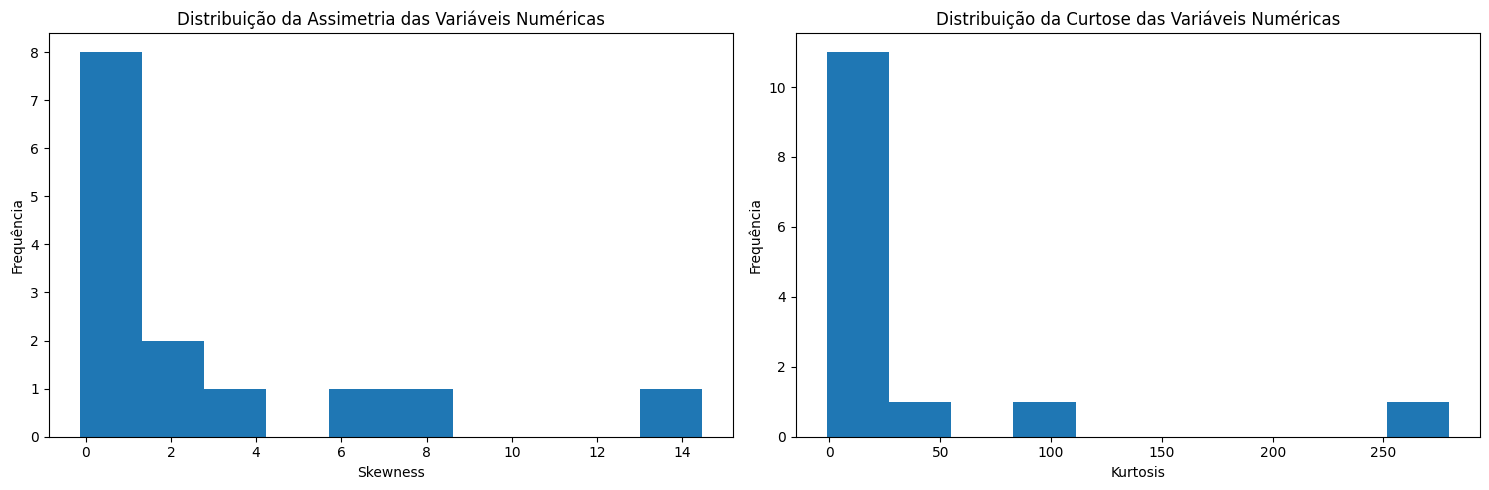

In [62]:
# Criar uma figura com 1 linha e 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma Skewness (Assimetria): negativo = cauda esquerda, positivo = cauda direita, 0 = simetria
axes[0].hist(d5.T.values.flatten(), bins=10)
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição da Assimetria das Variáveis Numéricas')
axes[0].set_xlabel('Skewness')

# Histograma Kurtosis (Curtose): relacionada ao comportamento das caudas e à ocorrência de valores extremos
axes[1].hist(d6.T.values.flatten(), bins=10)
axes[1].set_ylabel('Frequência')
axes[1].set_title('Distribuição da Curtose das Variáveis Numéricas')
axes[1].set_xlabel('Kurtosis')

# Ajustar o espaçamento
plt.tight_layout()

# Exibir os gráficos
plt.show()

## 1.4.2 Categorical Attributes

In [63]:
categorical_att.apply(lambda x: x.unique().shape[0])

merchant_category               12
card_type                        5
auth_method                      5
channel                          5
device_type                      8
is_foreign_transaction           2
is_new_merchant                  2
used_vpn                         2
ip_country_mismatch              2
billing_shipping_mismatch        2
is_ai_generated_scam_attempt     2
dtype: int64

# 2.0 FEATURE ENGINEERING

## Mapa mental de hipóteses

- Fenômeno: Satisfação do cliente (variável dependente ou resposta = y).
- Agentes: Variáveis que impactam o fenômeno (variáveis independentes = x)
- Atributos do agente: características dos atributos.

## 2.1 Criação das hipóteses

### Hipóteses com dados disponíveis:
#### 2.1.1 Serviços de Conveniência

**1** Facilidade de autoserviço online de agendamento aumenta o nível de satisfação do cliente.

## 2.2 Lista final de hipóteses

**1** Facilidade de autoserviço online de agendamento aumenta o nível de satisfação do cliente.

### Feature Engineering

In [64]:
df3 = df2.copy()

In [65]:
del (df2)

# 3.0 ANÁLISE EXPLORATÓRIA DOS DADOS - EDA

## 3.1 Análise Exploratória Univariada

### 3.1.1 Numerical Variable

array([[<Axes: title={'center': 'amount_usd'}>,
        <Axes: title={'center': 'hours_since_last_txn'}>,
        <Axes: title={'center': 'txn_count_last_24h'}>,
        <Axes: title={'center': 'distance_from_home_km'}>],
       [<Axes: title={'center': 'card_age_months'}>,
        <Axes: title={'center': 'customer_age'}>,
        <Axes: title={'center': 'account_balance_usd'}>,
        <Axes: title={'center': 'cvv_retry_count'}>],
       [<Axes: title={'center': 'velocity_score'}>,
        <Axes: title={'center': 'time_of_day_hour'}>,
        <Axes: title={'center': 'day_of_week'}>,
        <Axes: title={'center': 'merchant_risk_score'}>],
       [<Axes: title={'center': 'prior_disputes'}>,
        <Axes: title={'center': 'is_fraud'}>, <Axes: >, <Axes: >]],
      dtype=object)

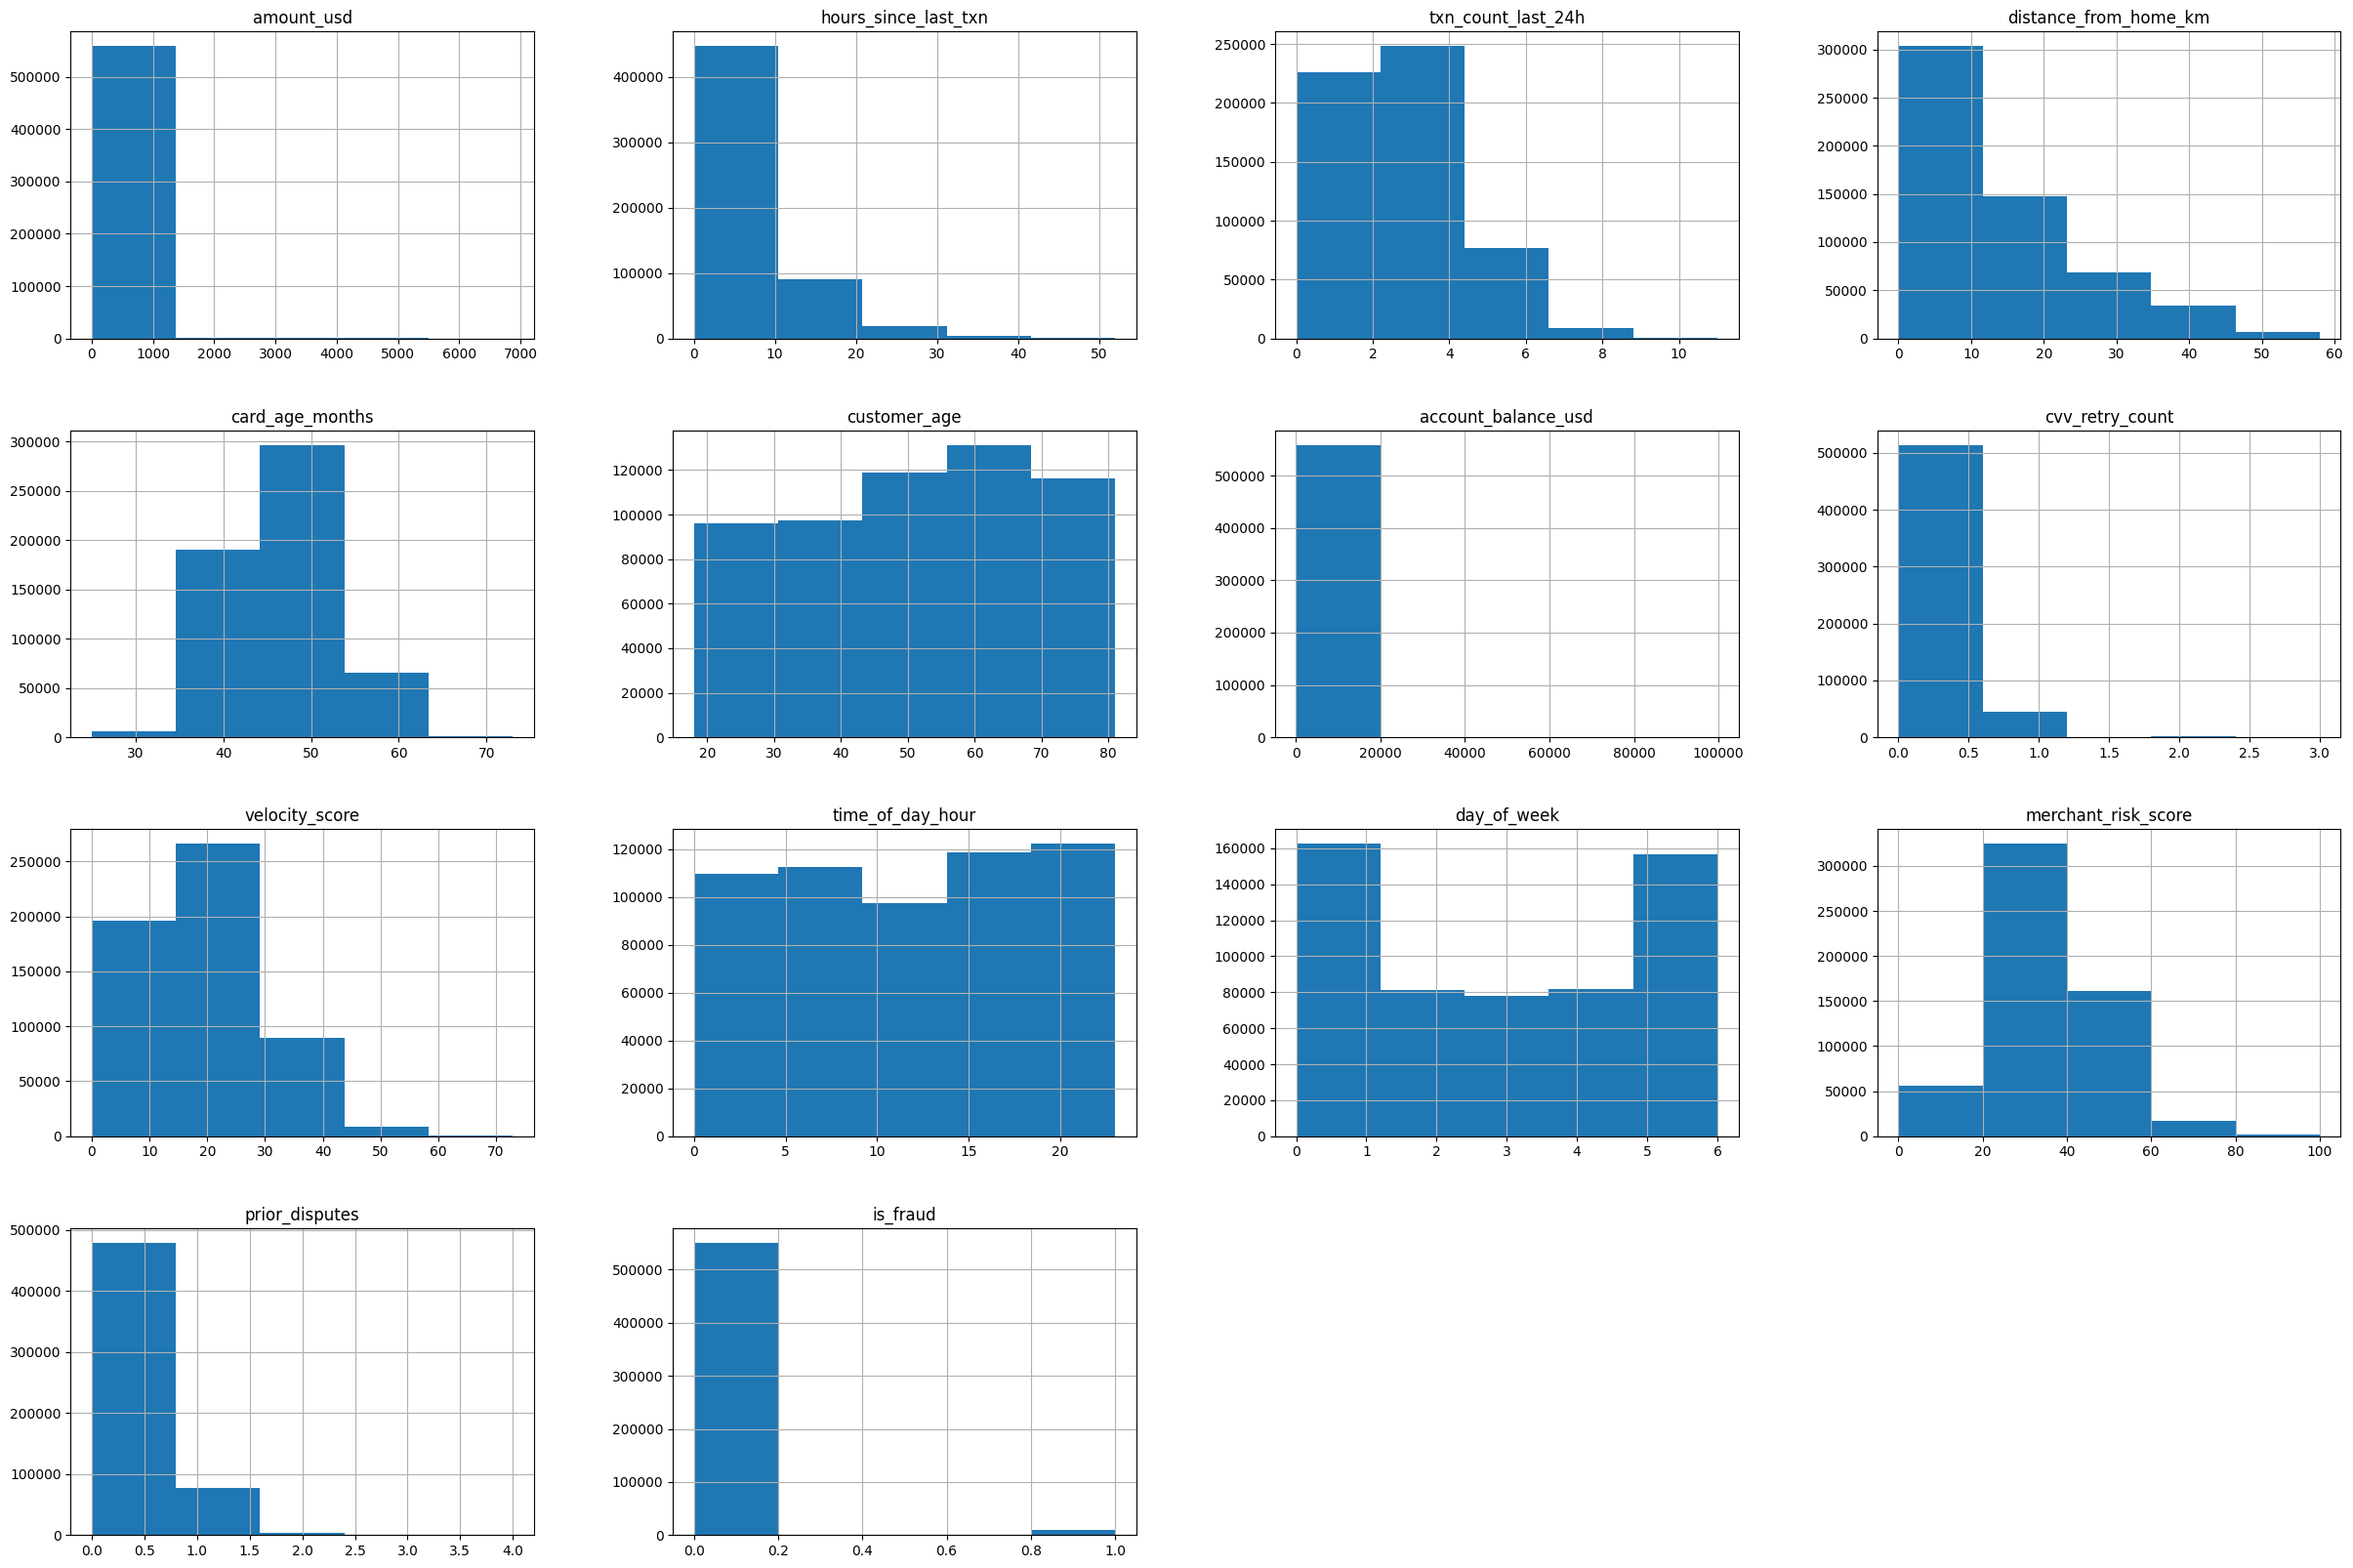

In [66]:
numerical_att.hist(bins=5, figsize=(30,20))

### 3.1.2 Categorical Variables

In [67]:
categorical_att.columns

Index(['merchant_category', 'card_type', 'auth_method', 'channel',
       'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn',
       'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

In [68]:
categorical_att.apply(lambda x: x.unique().shape[0])

merchant_category               12
card_type                        5
auth_method                      5
channel                          5
device_type                      8
is_foreign_transaction           2
is_new_merchant                  2
used_vpn                         2
ip_country_mismatch              2
billing_shipping_mismatch        2
is_ai_generated_scam_attempt     2
dtype: int64

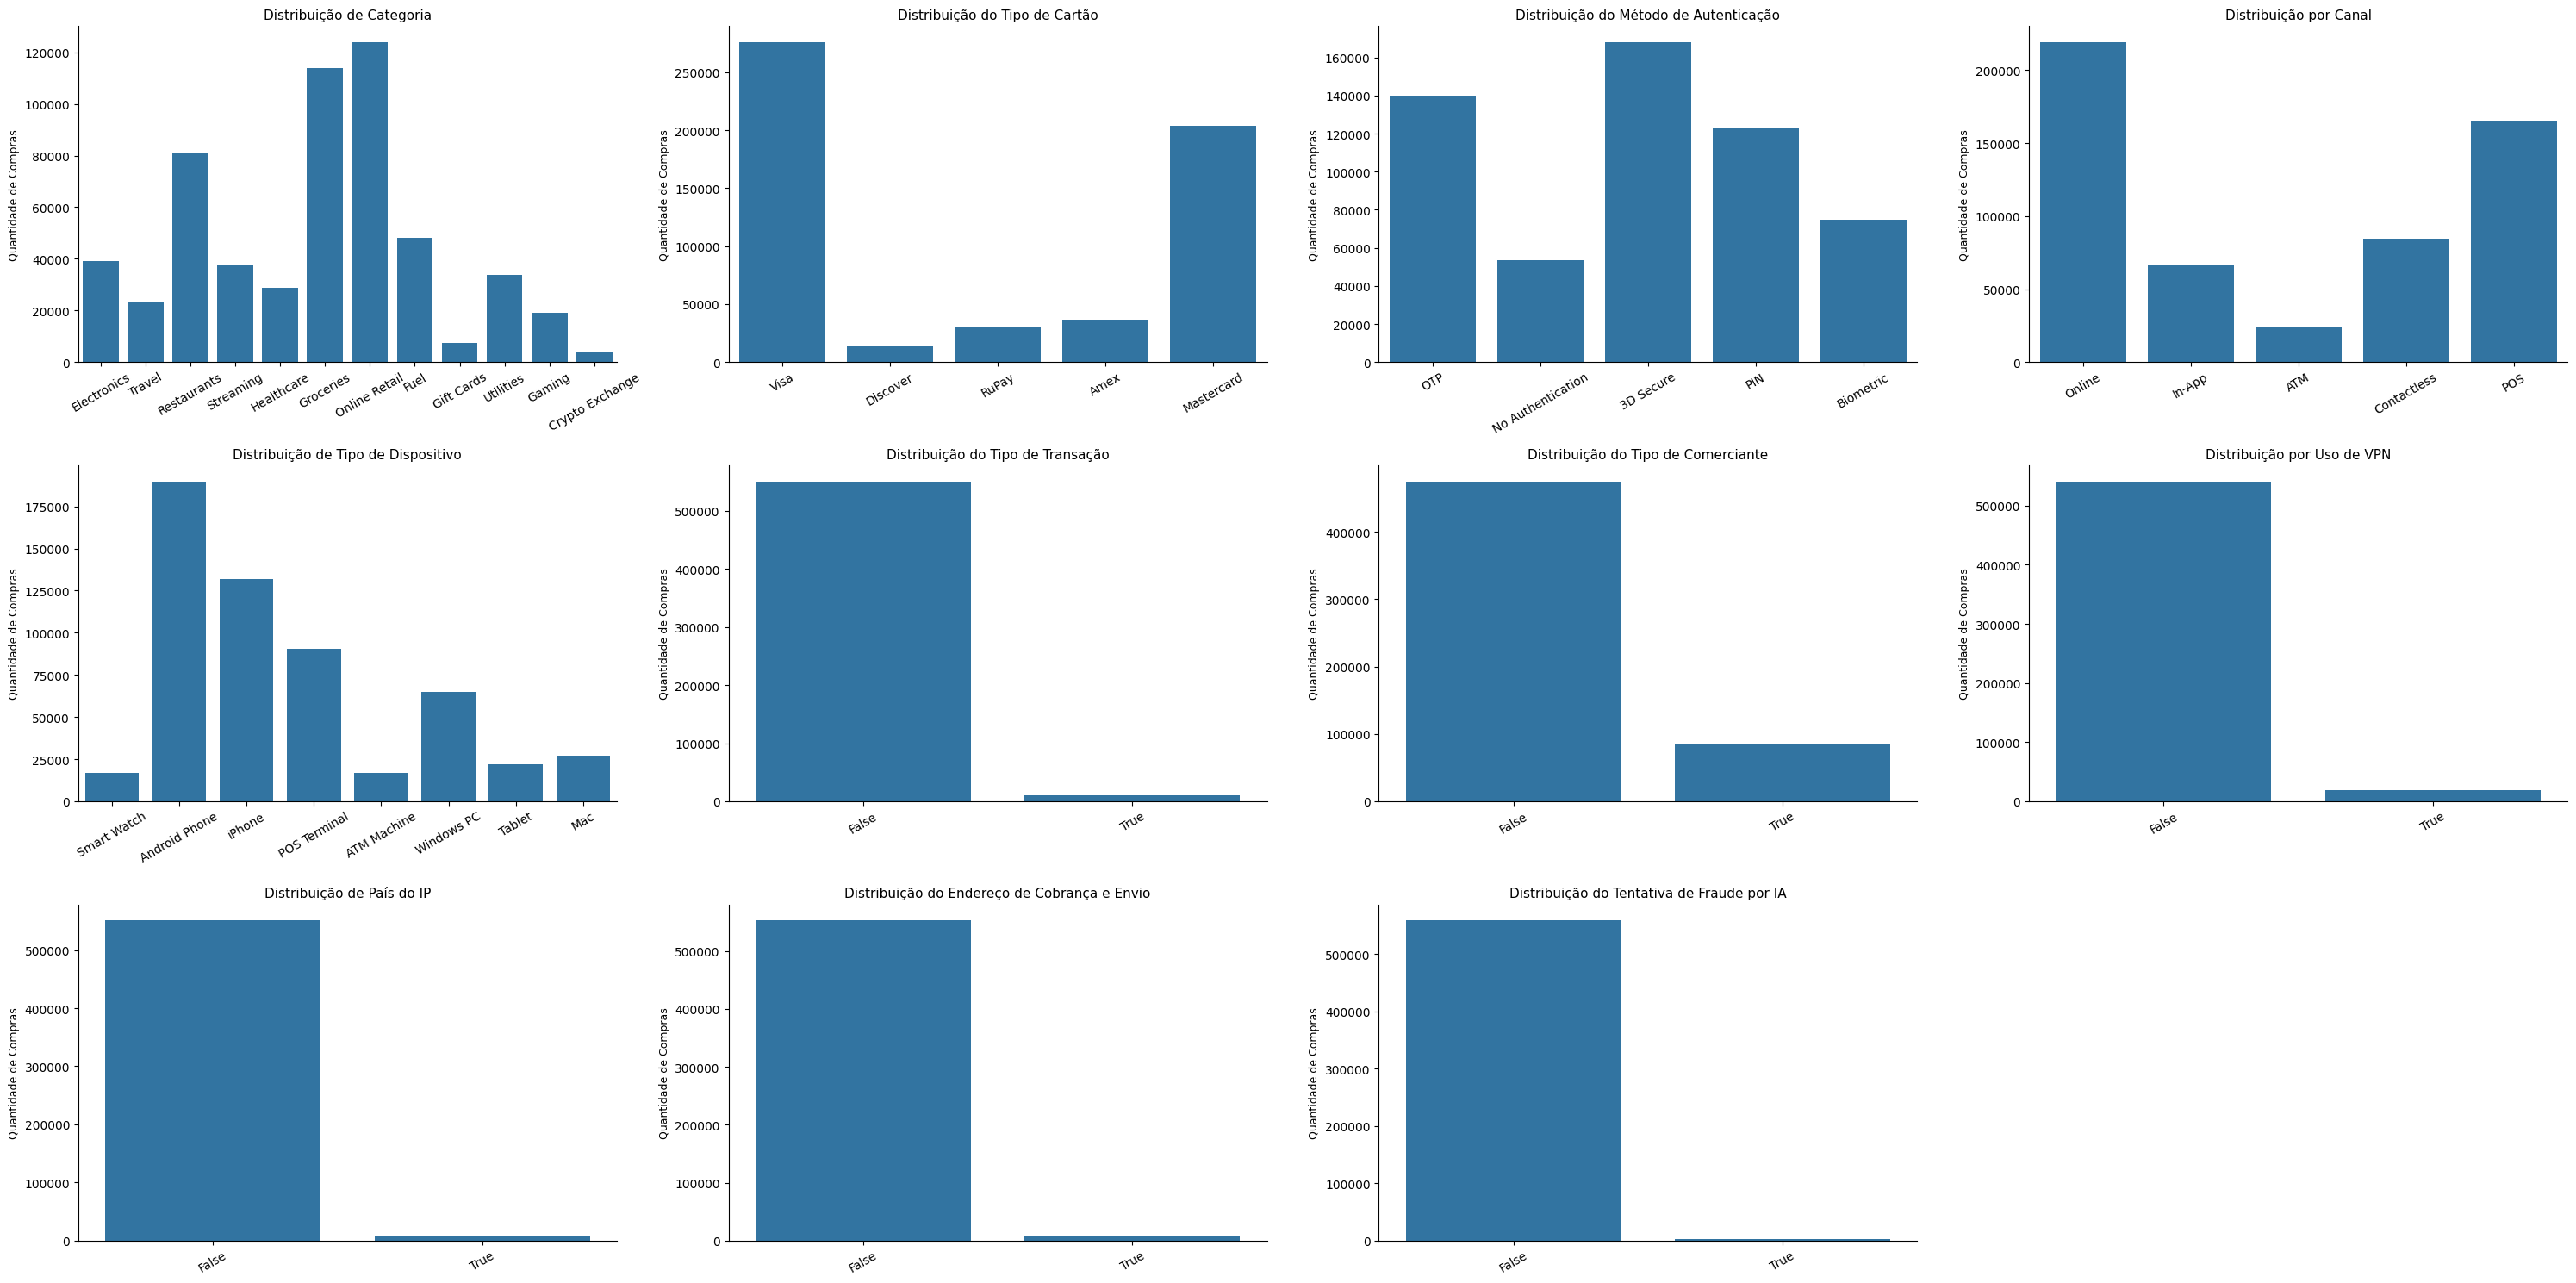

In [70]:
# Criar figura com 3 linhas e 4 colunas
fig, axes = plt.subplots(3, 4, figsize=(30, 15))

# Transformar a matriz de eixos em uma lista
axes = axes.flatten()

# Lista das variáveis
variaveis = [
    'merchant_category', 'card_type', 'auth_method', 'channel',
    'device_type', 'is_foreign_transaction', 'is_new_merchant',
    'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
    'is_ai_generated_scam_attempt'
]

# Lista dos títulos
titulos = [
    'Distribuição de Categoria',
    'Distribuição do Tipo de Cartão',
    'Distribuição do Método de Autenticação',
    'Distribuição por Canal',
    'Distribuição de Tipo de Dispositivo',
    'Distribuição do Tipo de Transação',
    'Distribuição do Tipo de Comerciante',
    'Distribuição por Uso de VPN',
    'Distribuição de País do IP',
    'Distribuição do Endereço de Cobrança e Envio',
    'Distribuição do Tentativa de Fraude por IA'
]

# Criar os gráficos
for ax, variavel, titulo in zip(axes, variaveis, titulos):

    sns.countplot(data=df3, x=variavel, ax=ax)

    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Quantidade de Compras', fontsize=9)

    # Rotacionar rótulos
    ax.tick_params(axis='x', rotation=30)

    # Remover bordas superiores e laterais
    sns.despine(ax=ax)

# Remover o último espaço vazio
fig.delaxes(axes[-1])

# Ajustar espaçamento
plt.tight_layout()

# Exibir gráficos
plt.show()

## 3.2 Análise Exploratória Bivariada

### 3.2.1 Análise Numérica Exploratória Bivariada

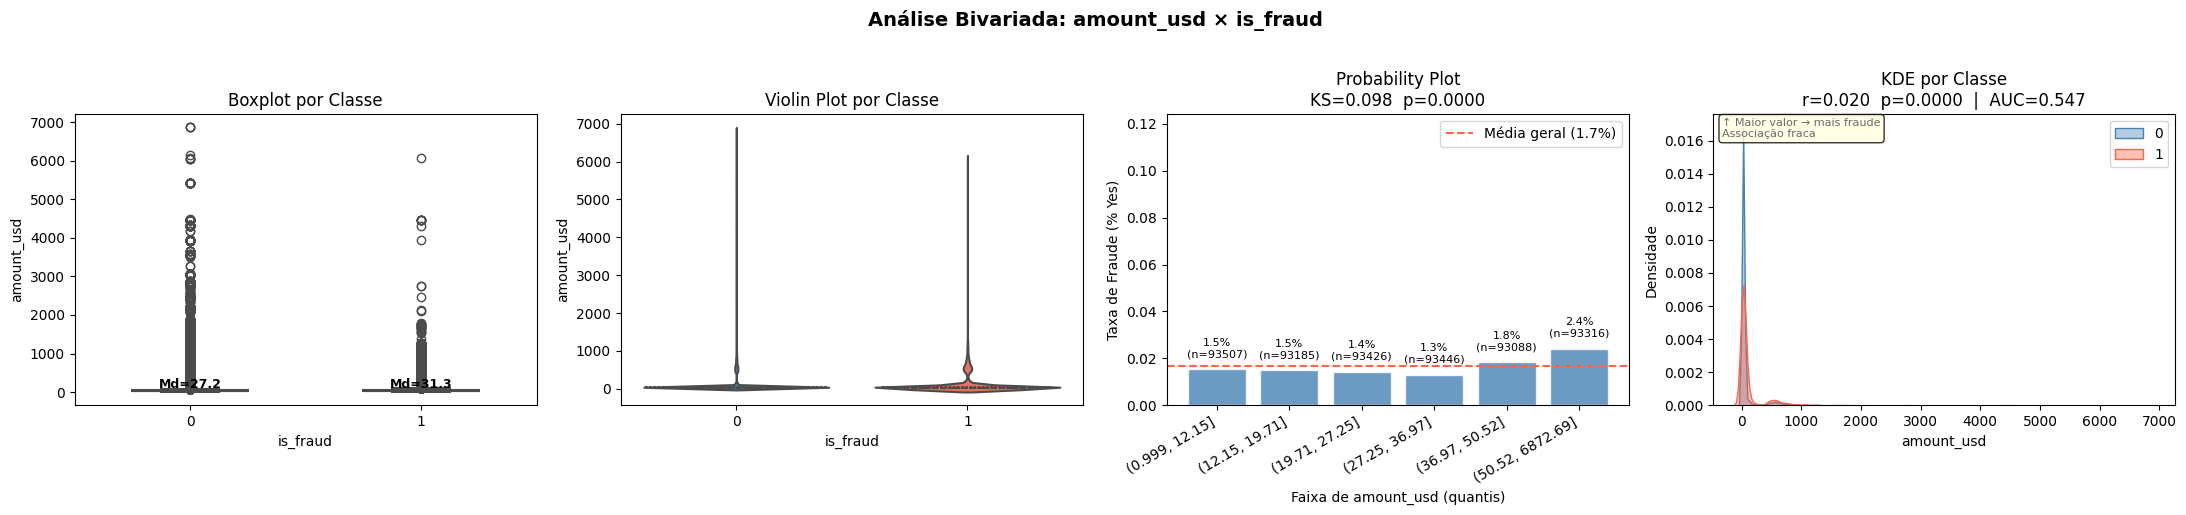

─────────────────────────────────────────────────────────────────
  amount_usd
  KS=0.0976  p=0.0000  |  r=0.0200  |  AUC=0.5468  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



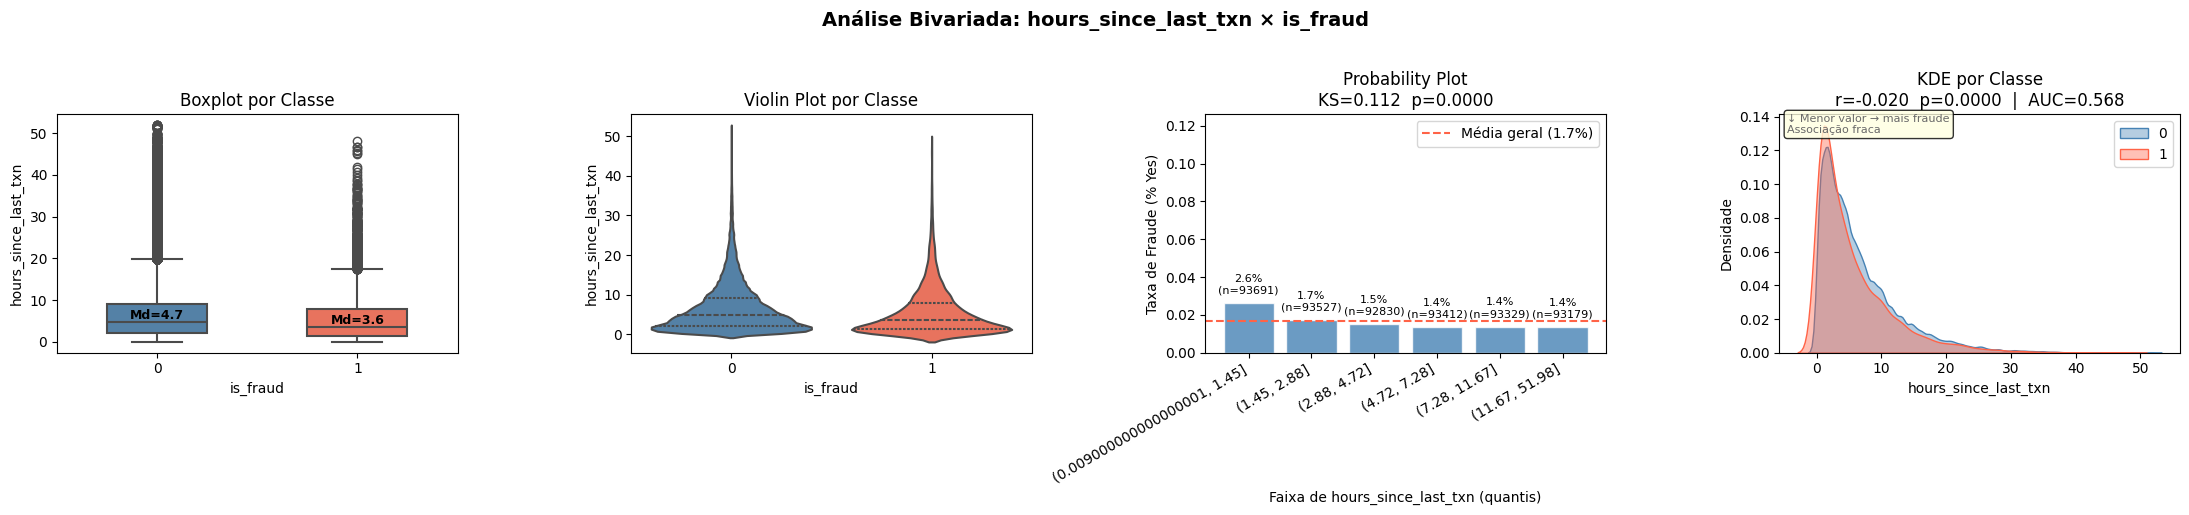

─────────────────────────────────────────────────────────────────
  hours_since_last_txn
  KS=0.1119  p=0.0000  |  r=-0.0204  |  AUC=0.5676  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



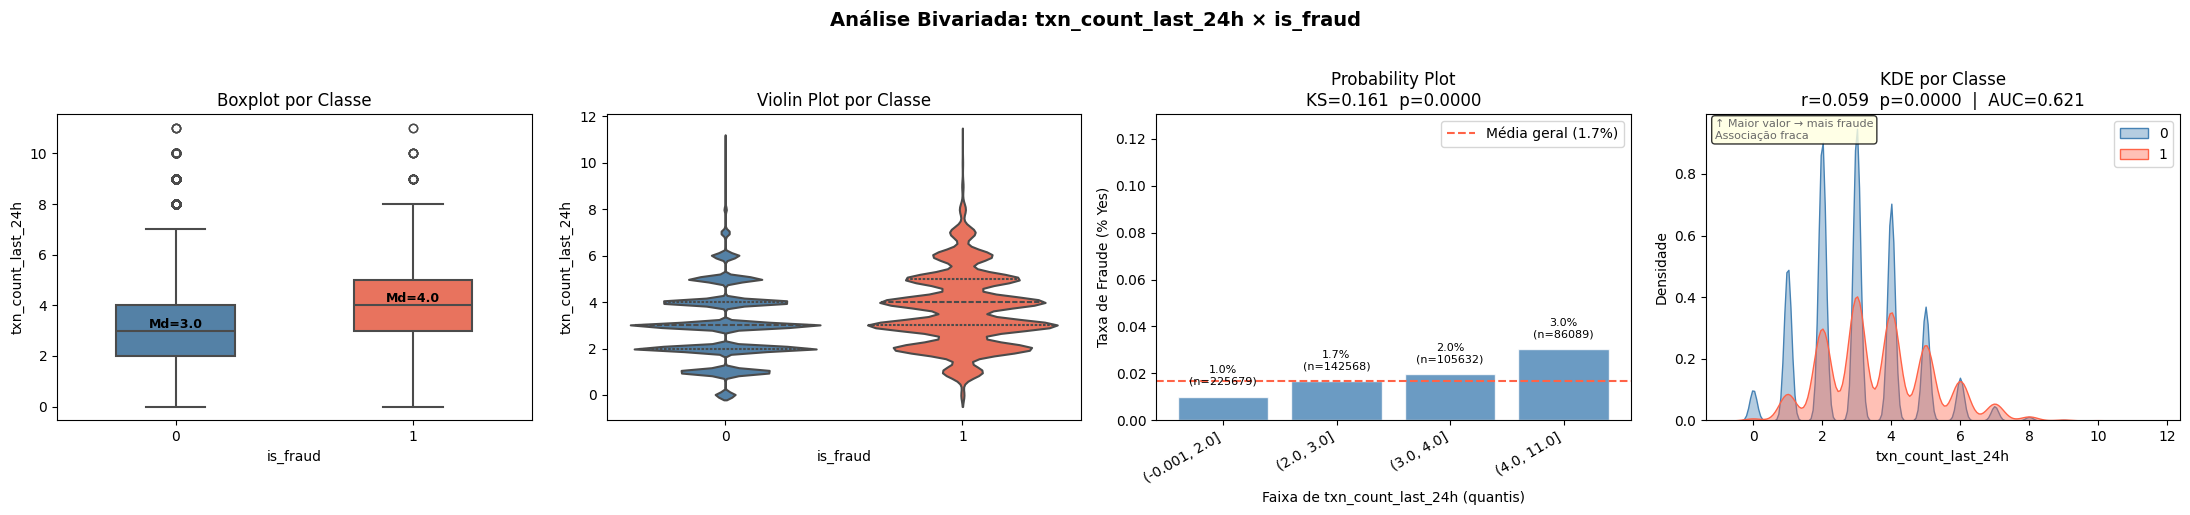

─────────────────────────────────────────────────────────────────
  txn_count_last_24h
  KS=0.1612  p=0.0000  |  r=0.0587  |  AUC=0.6210  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



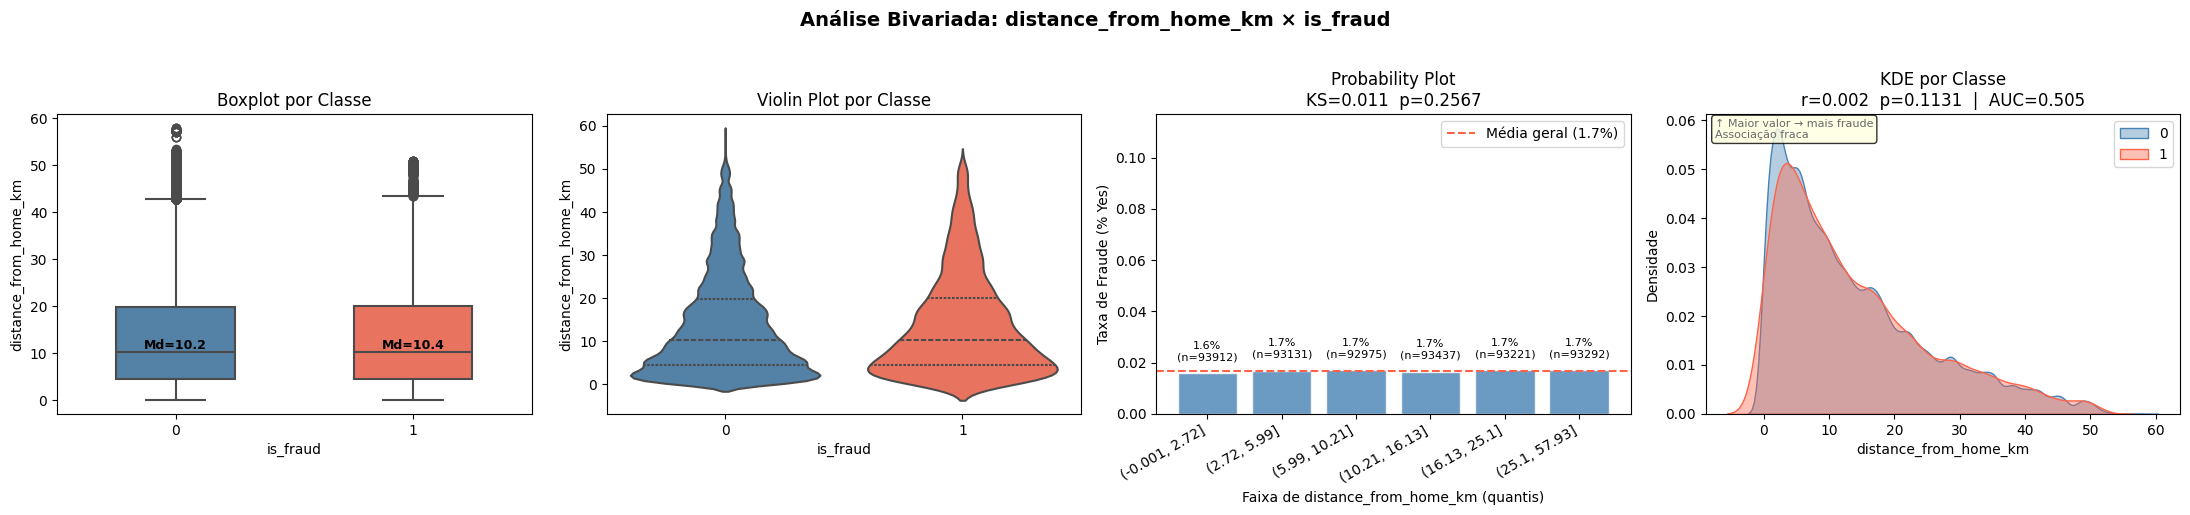

─────────────────────────────────────────────────────────────────
  distance_from_home_km
  KS=0.0105  p=0.2567  |  r=0.0021  |  AUC=0.5053  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



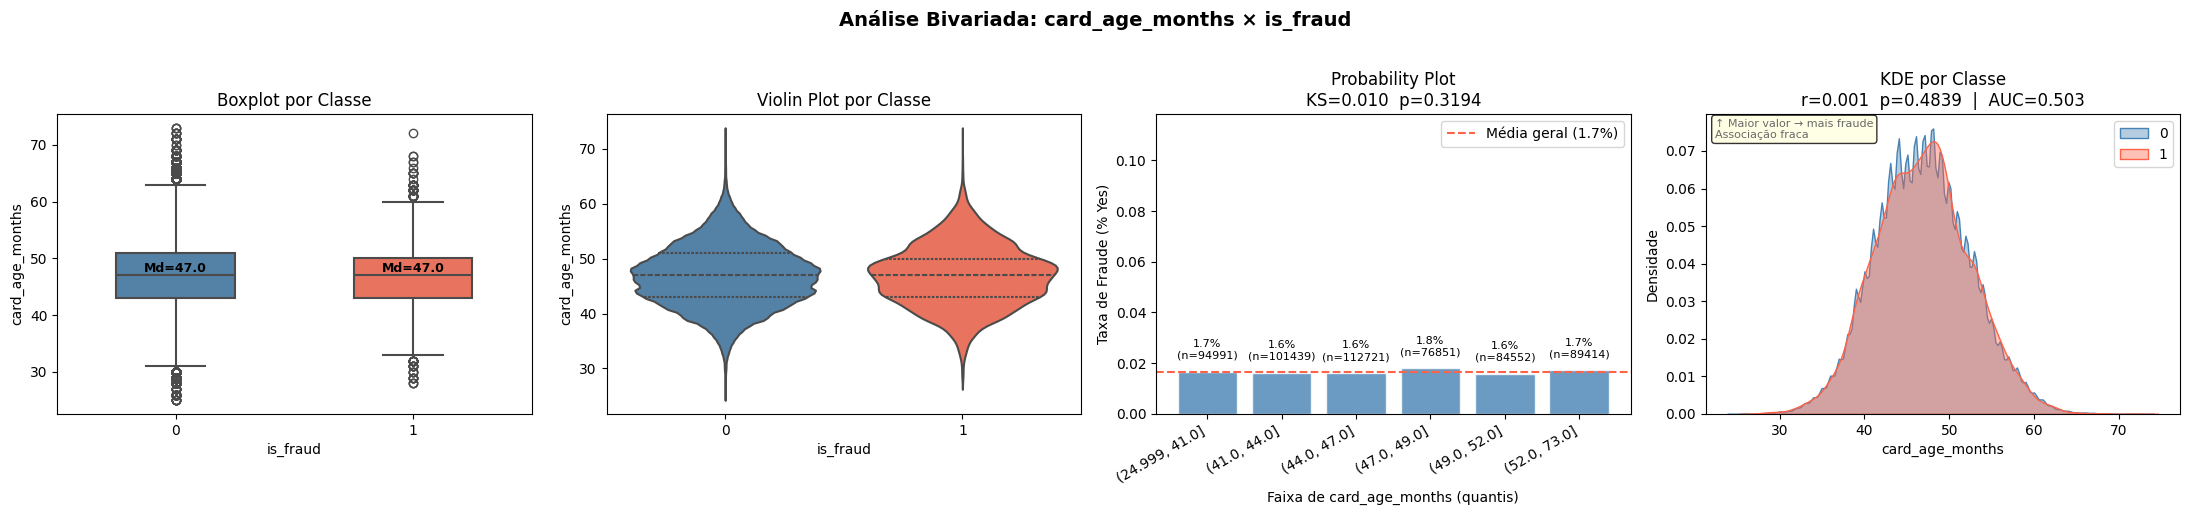

─────────────────────────────────────────────────────────────────
  card_age_months
  KS=0.0100  p=0.3194  |  r=0.0009  |  AUC=0.5030  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



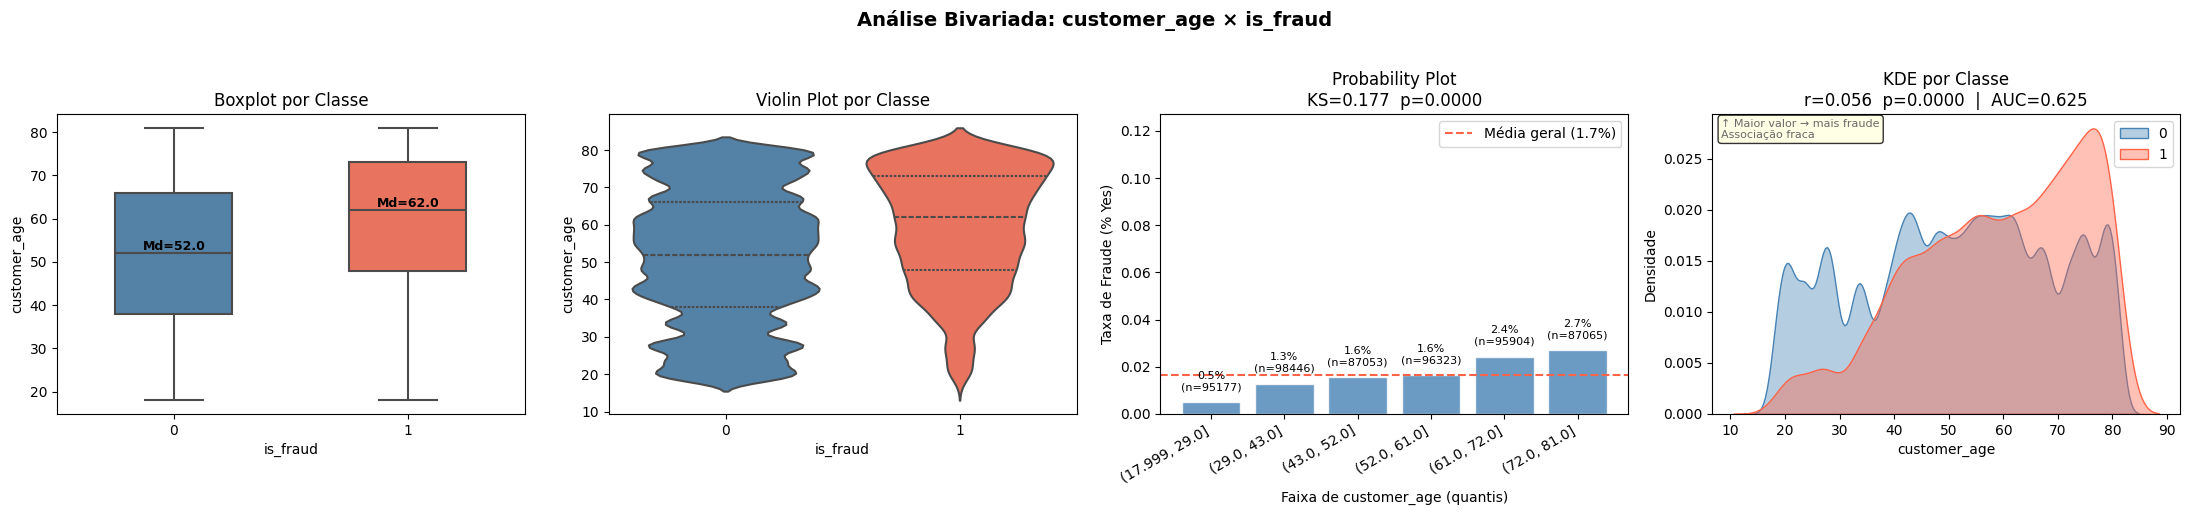

─────────────────────────────────────────────────────────────────
  customer_age
  KS=0.1767  p=0.0000  |  r=0.0564  |  AUC=0.6255  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



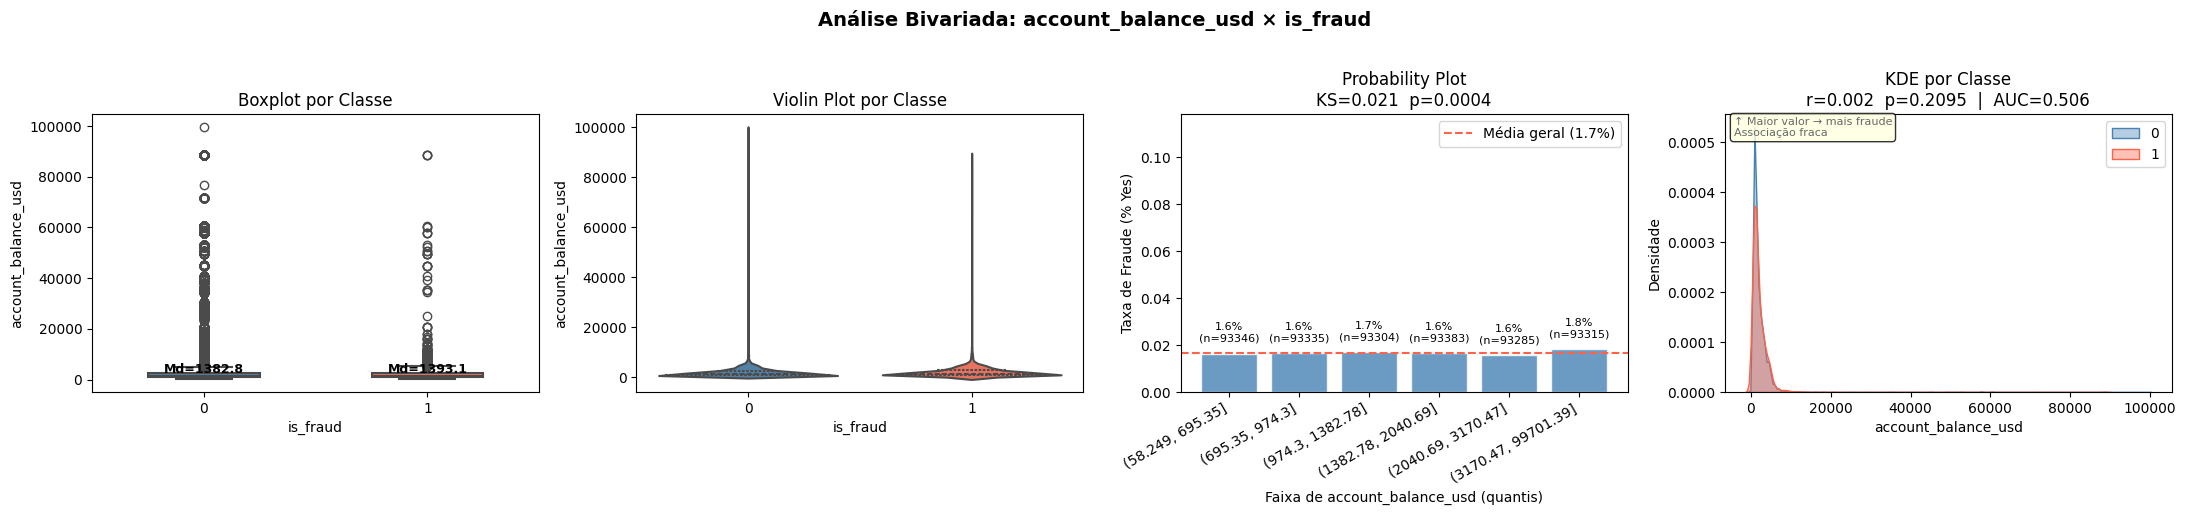

─────────────────────────────────────────────────────────────────
  account_balance_usd
  KS=0.0214  p=0.0004  |  r=0.0017  |  AUC=0.5057  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



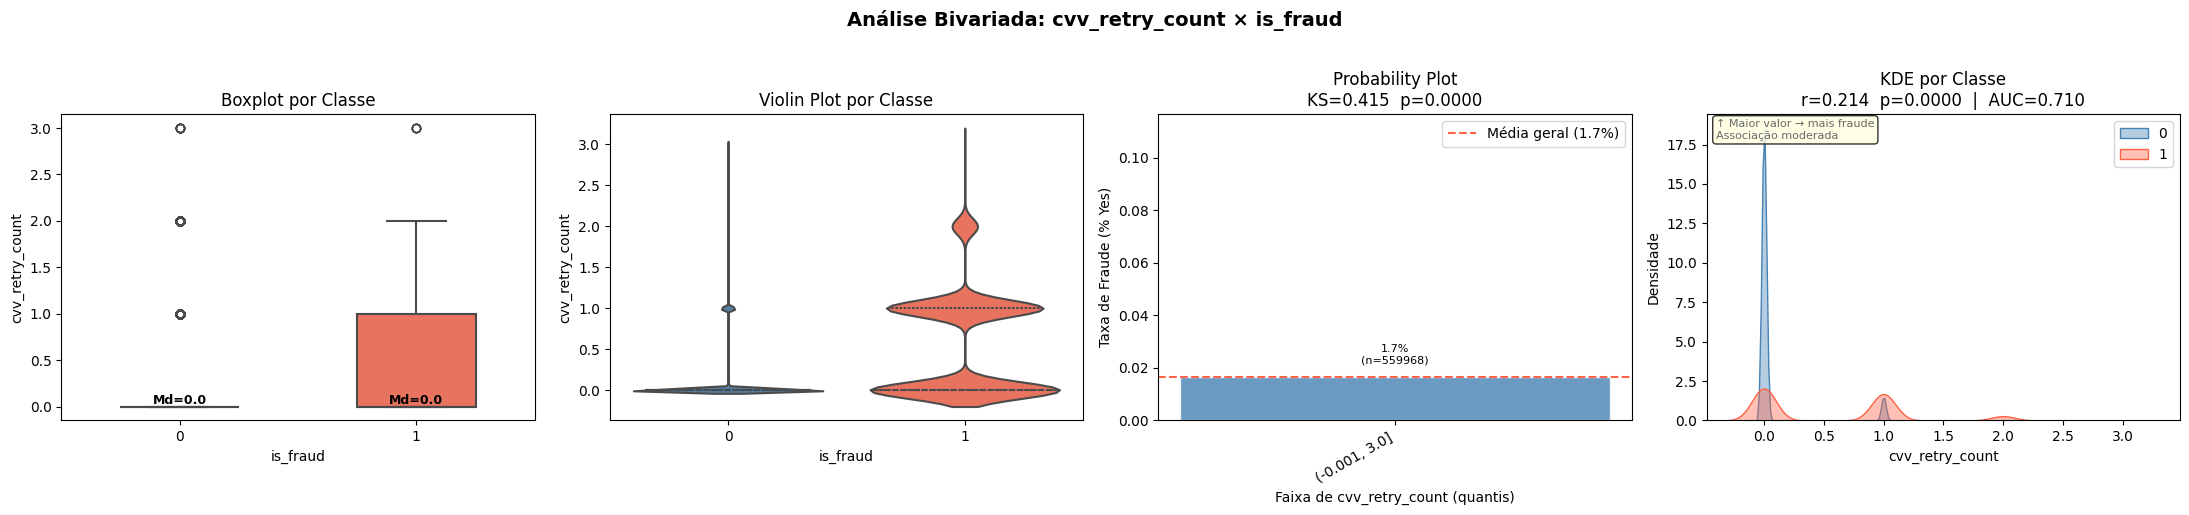

─────────────────────────────────────────────────────────────────
  cvv_retry_count
  KS=0.4147  p=0.0000  |  r=0.2139  |  AUC=0.7096  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



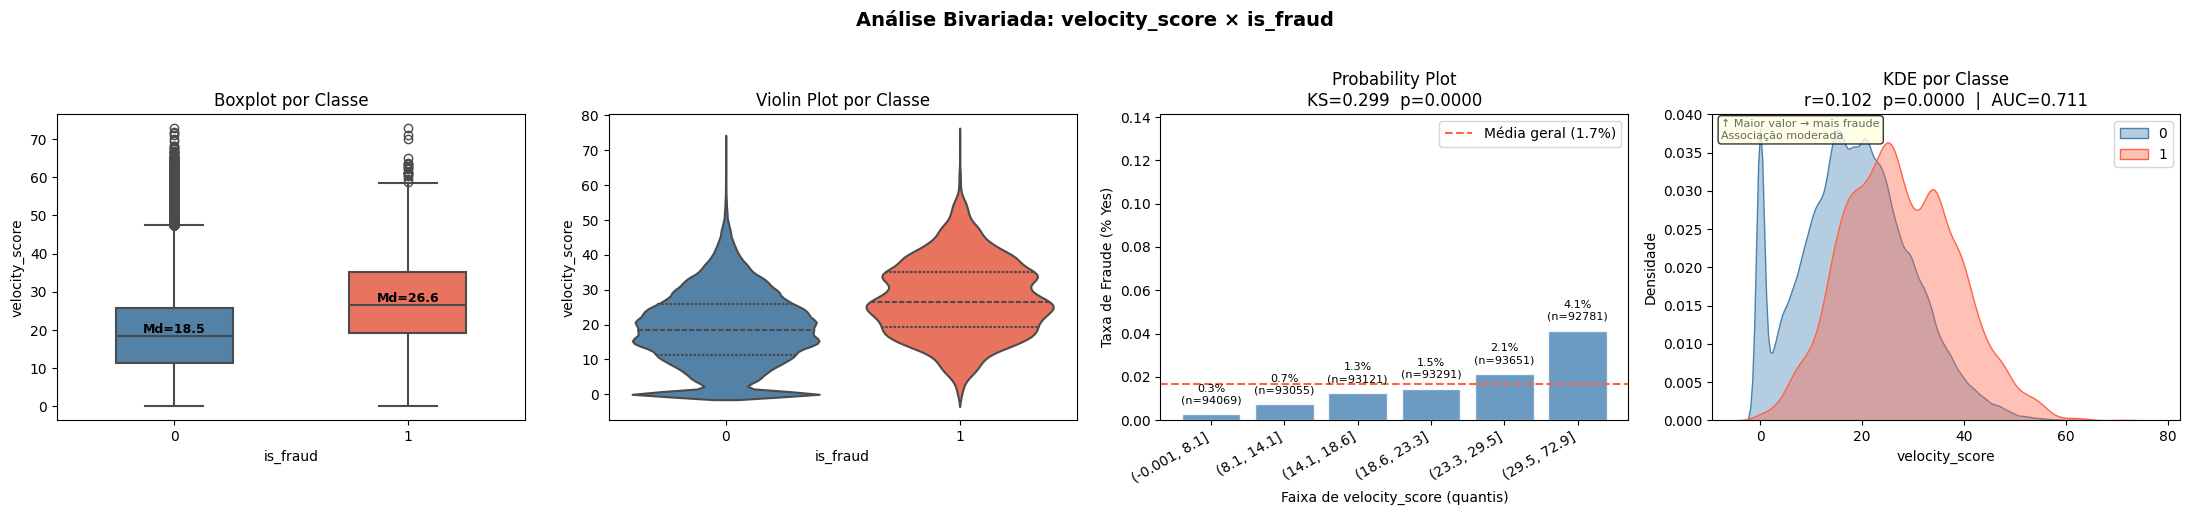

─────────────────────────────────────────────────────────────────
  velocity_score
  KS=0.2986  p=0.0000  |  r=0.1019  |  AUC=0.7109  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



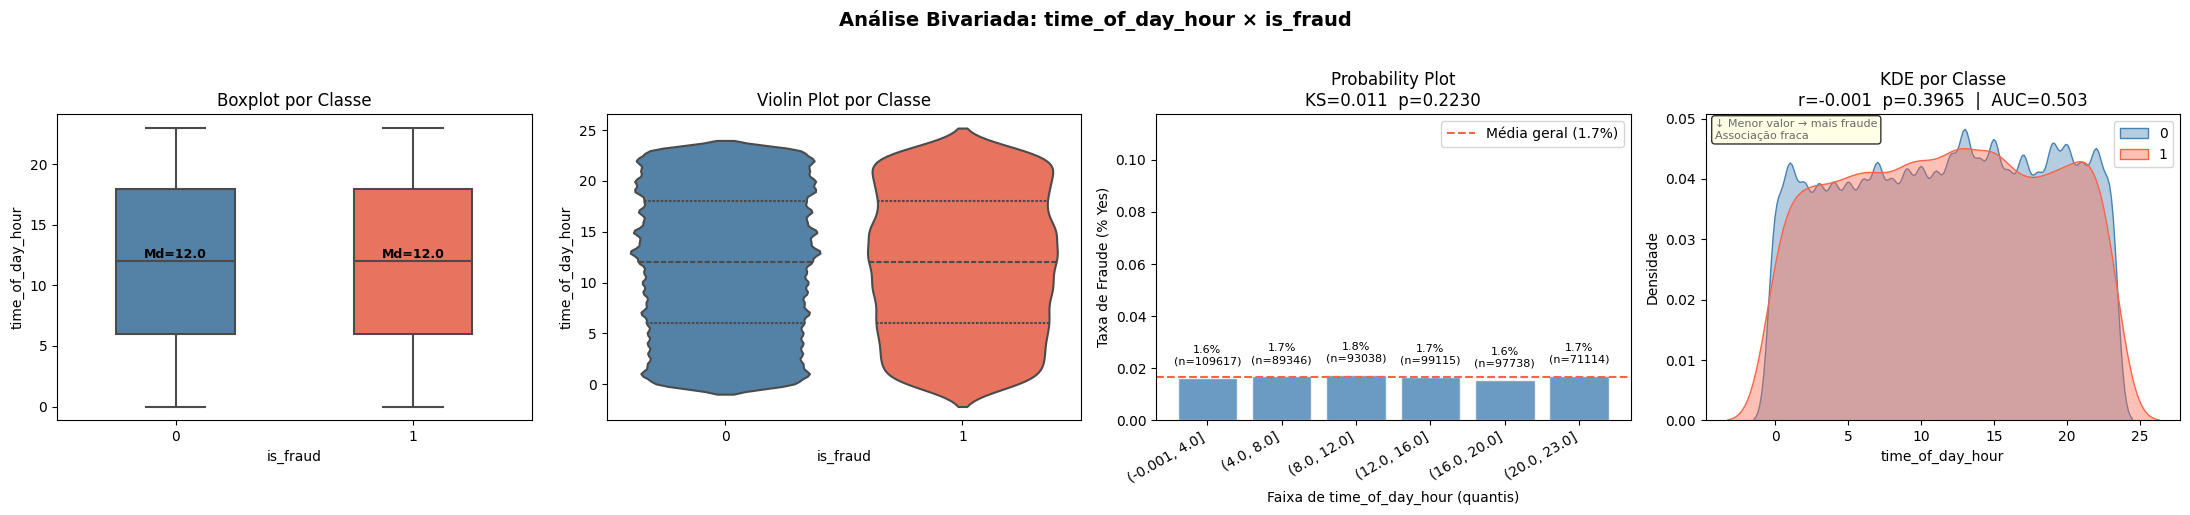

─────────────────────────────────────────────────────────────────
  time_of_day_hour
  KS=0.0109  p=0.2230  |  r=-0.0011  |  AUC=0.5027  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



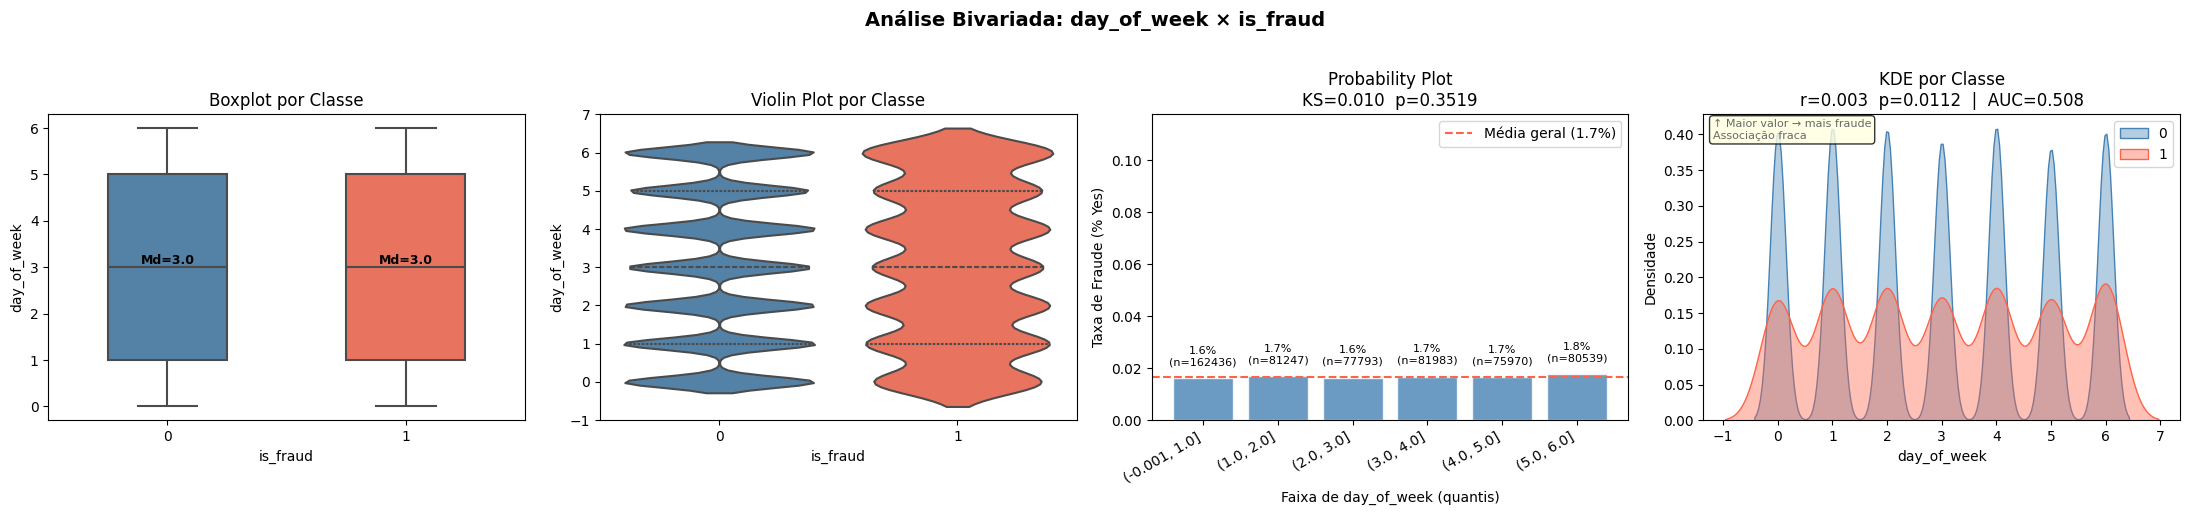

─────────────────────────────────────────────────────────────────
  day_of_week
  KS=0.0097  p=0.3519  |  r=0.0034  |  AUC=0.5076  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



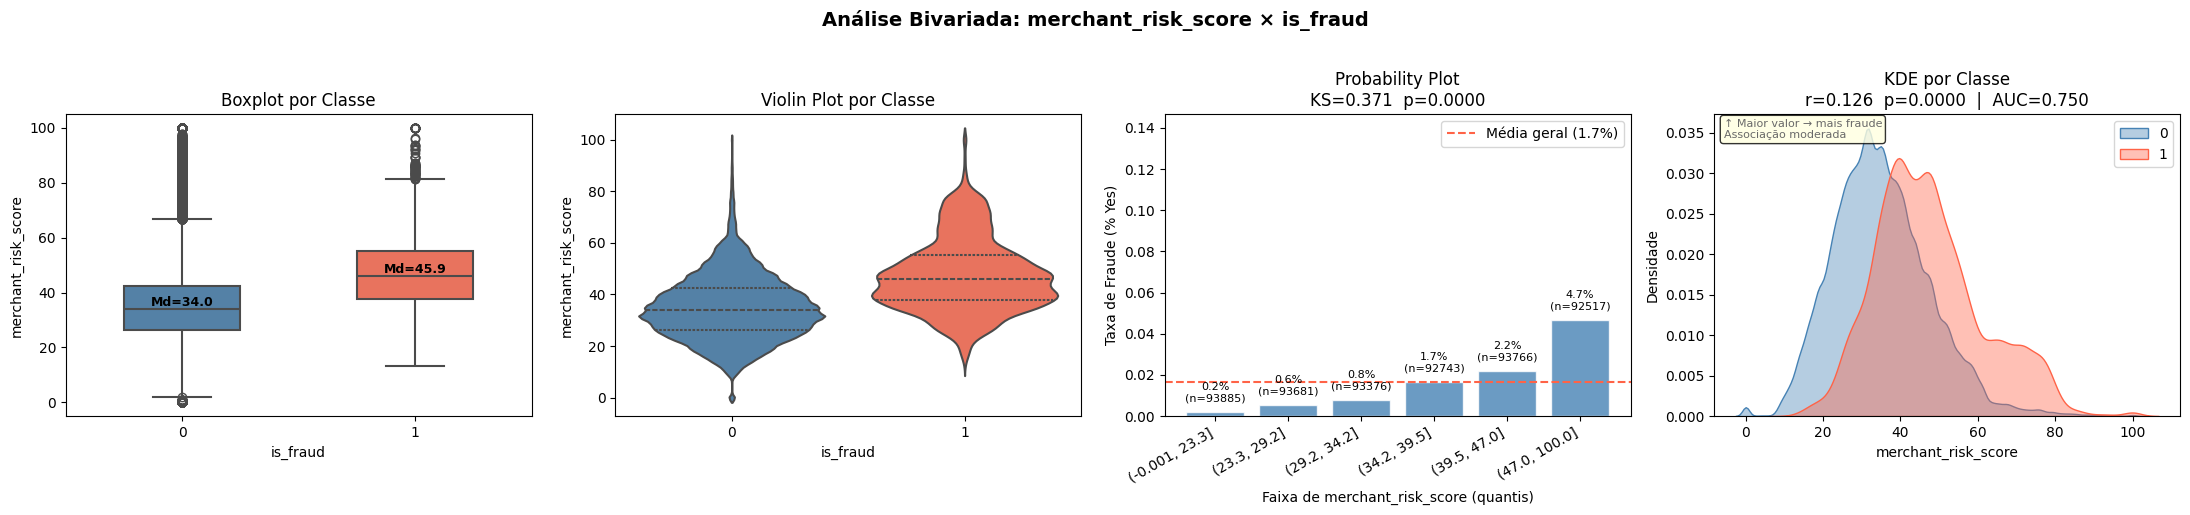

─────────────────────────────────────────────────────────────────
  merchant_risk_score
  KS=0.3712  p=0.0000  |  r=0.1261  |  AUC=0.7497  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



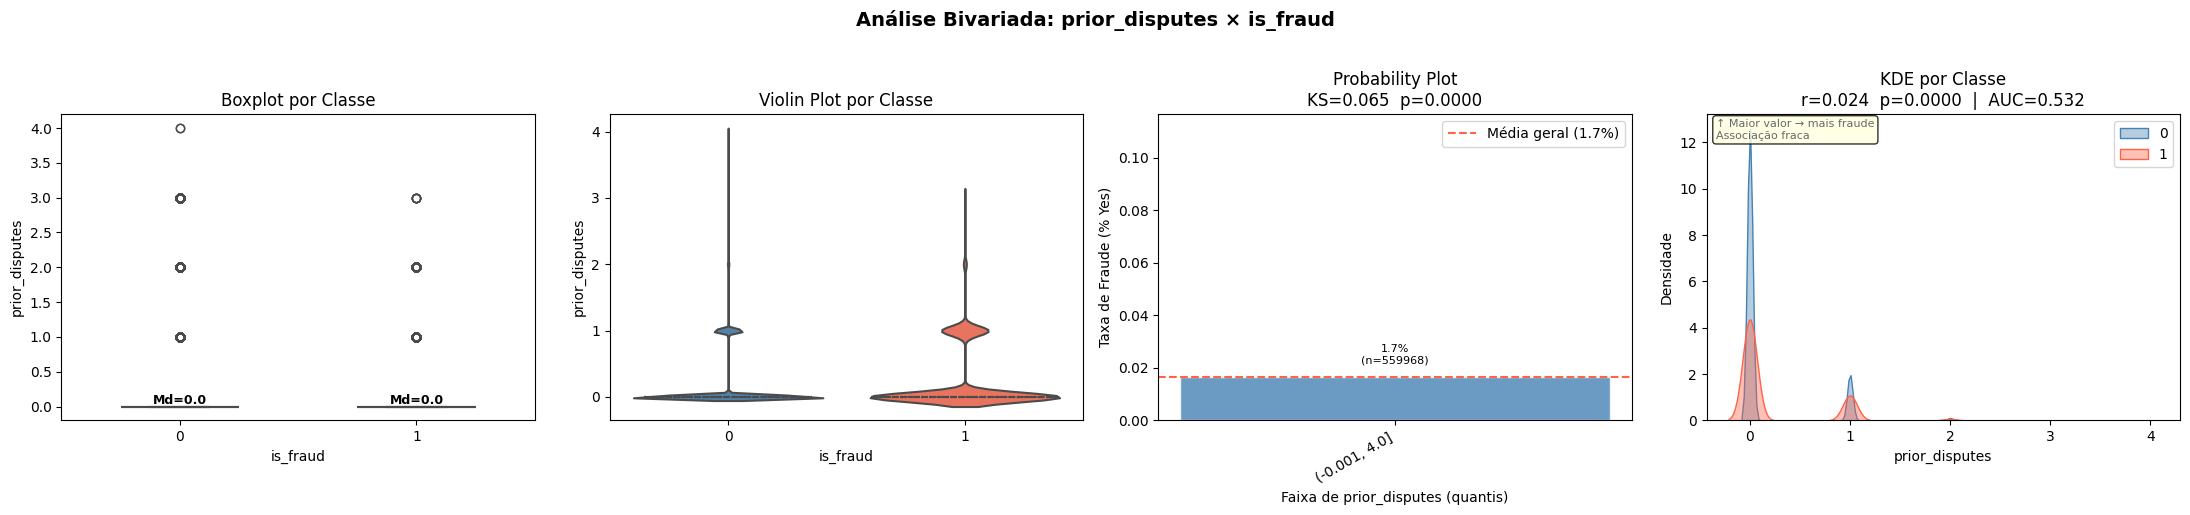

─────────────────────────────────────────────────────────────────
  prior_disputes
  KS=0.0646  p=0.0000  |  r=0.0238  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



In [74]:
# Análise Bivariada: Variáveis Numéricas × Variável Alvo
col_target = 'is_fraud'
y_binary   = (df3[col_target] == 1).astype(int)
num_cols = [cols for cols in numerical_att.columns if df3[cols].nunique() > 1 and cols != 'is_fraud']

for col in num_cols:
    g_no  = df3.loc[df3[col_target] == 0,  col].dropna() #passa dropna só por precaução
    g_yes = df3.loc[df3[col_target] == 1, col].dropna()
 
    # --- Métricas ---
    ks_stat, ks_p = stats.ks_2samp(g_no, g_yes)
    r_pb,    p_pb = pointbiserialr(y_binary, df3[col].fillna(df3[col].median()))
 
    x_col = df3[[col]].fillna(df3[col].median())
    model = LogisticRegression(max_iter=500).fit(x_col, y_binary)
    auc   = roc_auc_score(y_binary, model.predict_proba(x_col)[:, 1])
    auc   = max(auc, 1 - auc) #aqui passa a probabilidade de uma feature sozinha separar bem e classificar
    #a variável bem, acima de 55%, quer dizer que ela é uma variável boa. Mede o peso de classificação da variável
 
    #============================================================
    # --- Probability Plot: faixas por quantil ---
    #============================================================
   
    # pessoas que sairam dividido por todas as variáveis. Mede a probabilidade de pessoas daquelas faixa
    # de sair da empresa
 
    df_prob        = df3[[col, col_target]].copy()
    df_prob['y']   = y_binary
    taxa_geral     = y_binary.mean()
 
    try:
        df_prob['faixa'] = pd.qcut(df_prob[col], q=6, duplicates='drop')
    except ValueError:
        df_prob['faixa'] = pd.cut(df_prob[col], bins=6)
 
    prob_by_faixa = (
        df_prob.groupby('faixa', observed=True)['y']
        .agg(['mean', 'count'])
        .reset_index()
    )
    prob_by_faixa.columns = ['Faixa', 'Taxa Fraude', 'N']
    prob_by_faixa['Faixa'] = prob_by_faixa['Faixa'].astype(str)
 
    #============================================================
    # --- Plots --- Estrutura
    #============================================================
 
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {col_target}',
                 fontsize=14, fontweight='bold', y=1.02)
 
    #============================================================
    # ── Plot 1: Boxplot por classe ────────────
    #============================================================
 
    sns.boxplot(data=df3, x=col_target, y=col, ax=axes[0],
                hue=col_target,
                palette={0: 'steelblue', 1: 'tomato'},
                width=0.5, linewidth=1.5, legend=False)
 
    for i, (group, label) in enumerate([(g_no, 0), (g_yes, 1)]):
        med = group.median()
        axes[0].text(i, med, f'Md={med:.1f}',
                     ha='center', va='bottom',
                     fontsize=9, fontweight='bold', color='black')
 
    axes[0].set_title('Boxplot por Classe')
    axes[0].set_xlabel(col_target)
    axes[0].set_ylabel(col)
 
    #============================================================
    # ── Plot 2: Violin por classe ────────────
    #============================================================
 
    sns.violinplot(data=df3, x=col_target, y=col, ax=axes[1],
                   hue=col_target,
                   palette={0: 'steelblue', 1: 'tomato'},
                   inner='quartile', linewidth=1.5, legend=False)
 
    axes[1].set_title('Violin Plot por Classe')
    axes[1].set_xlabel(col_target)
    axes[1].set_ylabel(col)
 
    #============================================================
    # ── Plot 3: Probability Plot ───────────────────────
    #============================================================
 
    bars = axes[2].bar(
        prob_by_faixa['Faixa'], prob_by_faixa['Taxa Fraude'],
        color='steelblue', alpha=0.8, edgecolor='white'
    )
    axes[2].axhline(taxa_geral, color='tomato', linestyle='--',
                    linewidth=1.5, label=f'Média geral ({taxa_geral:.1%})')
 
    for bar, (_, row_data) in zip(bars, prob_by_faixa.iterrows()):
        axes[2].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.005,
                     f"{row_data['Taxa Fraude']:.1%}\n(n={int(row_data['N'])})",
                     ha='center', fontsize=8, color='black')
 
    axes[2].set_title(f'Probability Plot\nKS={ks_stat:.3f}  p={ks_p:.4f}')
    axes[2].set_xlabel(f'Faixa de {col} (quantis)')
    axes[2].set_ylabel('Taxa de Fraude (% Yes)')
    axes[2].set_xticks(range(len(prob_by_faixa)))
    axes[2].set_xticklabels(prob_by_faixa['Faixa'], rotation=30, ha='right')
    axes[2].set_ylim(0, prob_by_faixa['Taxa Fraude'].max() + 0.1)
    axes[2].legend()
 
    #============================================================
    # ── Plot 4: KDE por classe + correlação ponto-biserial ──
    #============================================================
 
    sns.kdeplot(g_no,  ax=axes[3], label=0,  fill=True, alpha=0.4, color='steelblue')
    sns.kdeplot(g_yes, ax=axes[3], label=1, fill=True, alpha=0.4, color='tomato')
 
    direction = '↑ Maior valor → mais fraude' if r_pb > 0 else '↓ Menor valor → mais fraude'
    strength  = 'forte' if abs(r_pb) > 0.3 else 'moderada' if abs(r_pb) > 0.1 else 'fraca'
 
    axes[3].set_title(f'KDE por Classe\nr={r_pb:.3f}  p={p_pb:.4f}  |  AUC={auc:.3f}')
    axes[3].set_xlabel(col)
    axes[3].set_ylabel('Densidade')
    axes[3].legend()
    axes[3].text(0.02, 0.92, f'{direction}\nAssociação {strength}',
                 transform=axes[3].transAxes, fontsize=8, color='dimgray',
                 bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
 
    plt.tight_layout()
    plt.show()
    plt.close(fig)
 
    #============================================================
    # --- Resumo textual ---
    #============================================================
 
    discriminacao = '🟢 Alta' if auc >= 0.65 else '🟡 Média' if auc >= 0.55 else '🔴 Baixa'
    print(f"{'─'*65}")
    print(f"  {col}")
    print(f"  KS={ks_stat:.4f}  p={ks_p:.4f}  |  r={r_pb:.4f}  |  AUC={auc:.4f}  |  Discriminação: {discriminacao}")
    print(f"{'─'*65}\n")

### 3.2.2 Análise Categórica Exploratória Bivariada

In [75]:
# Encoding categorical variables using LabelEncoder

x_enc = OneHotEncoder().fit_transform(df3[[col]])

C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


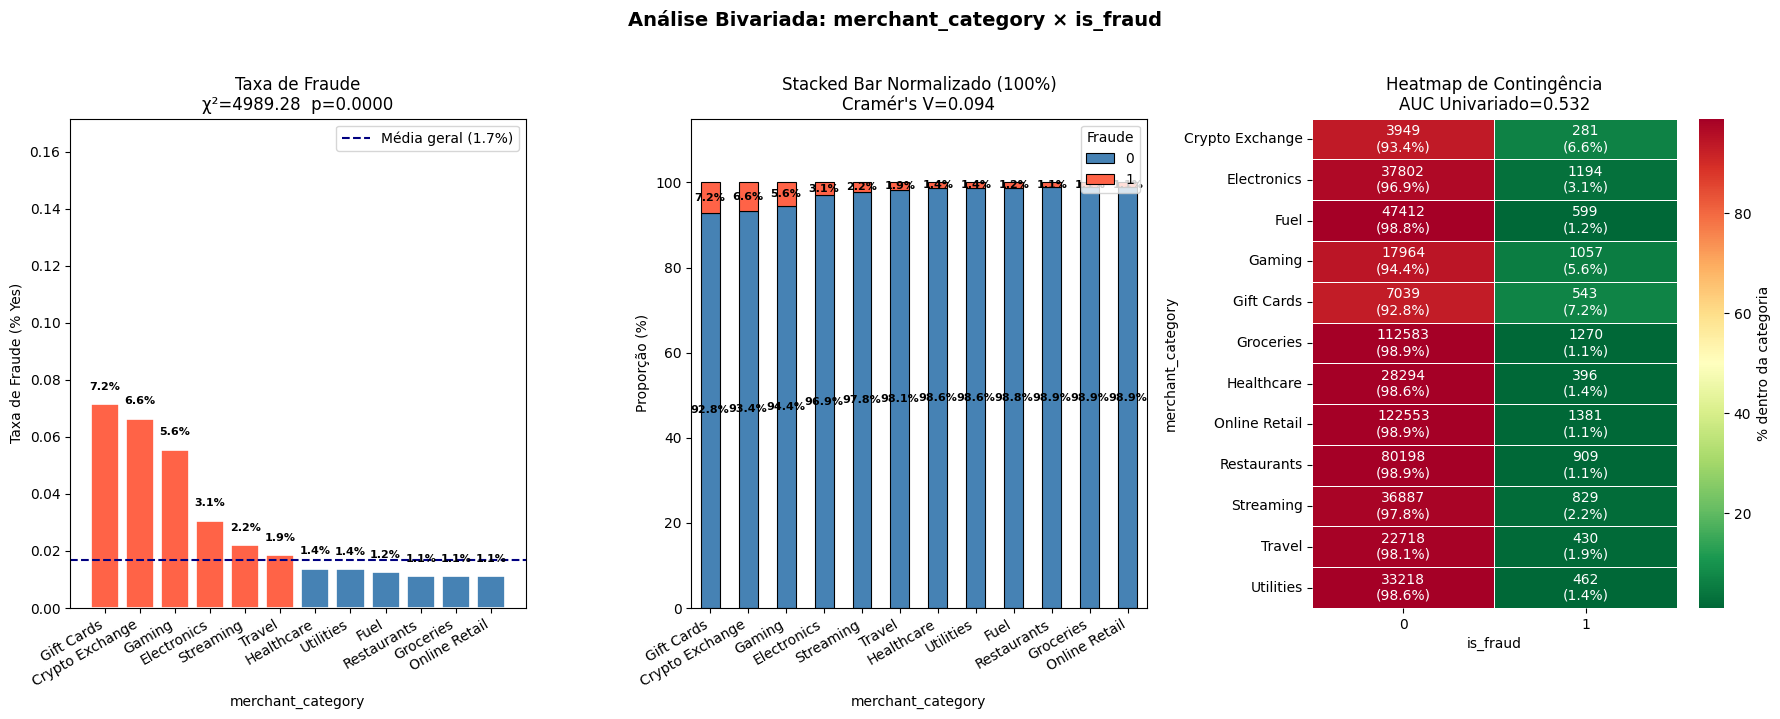

───────────────────────────────────────────────────────
  merchant_category
  χ²=4989.28  p=0.0000  |  Cramér's V=0.0943  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


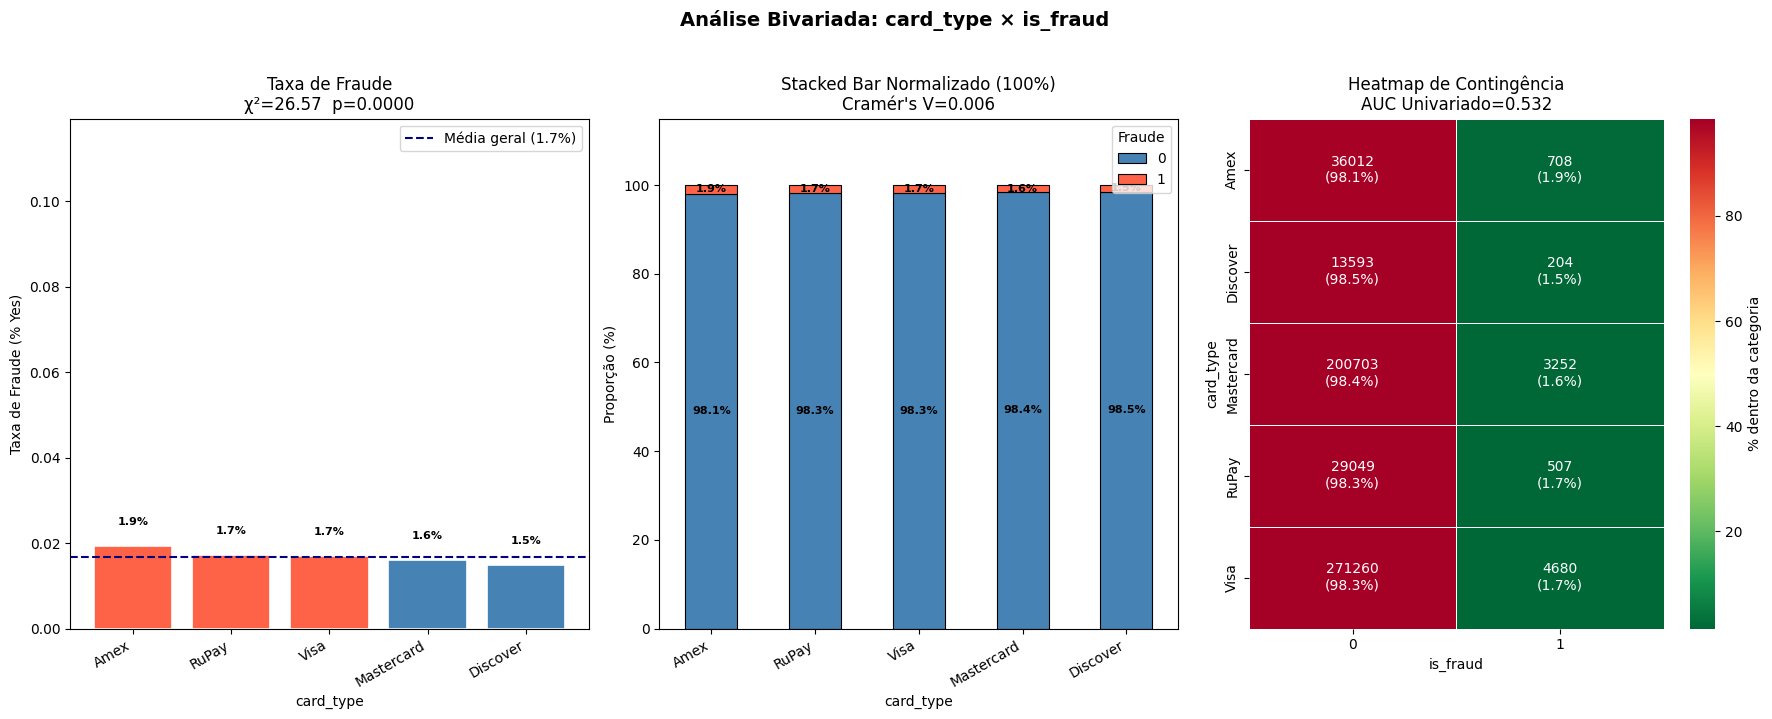

───────────────────────────────────────────────────────
  card_type
  χ²=26.57  p=0.0000  |  Cramér's V=0.0063  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


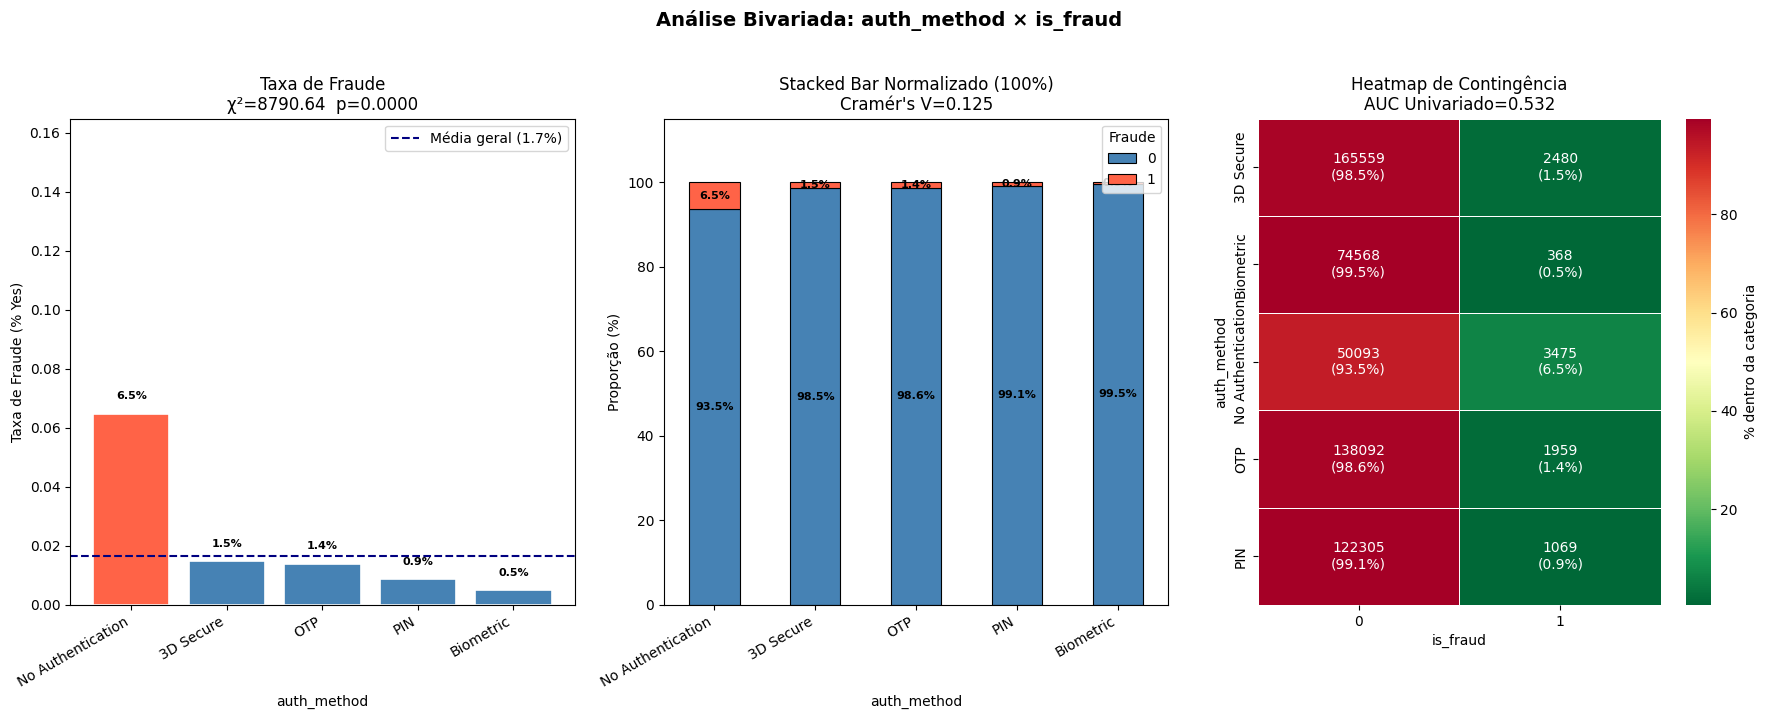

───────────────────────────────────────────────────────
  auth_method
  χ²=8790.64  p=0.0000  |  Cramér's V=0.1253  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


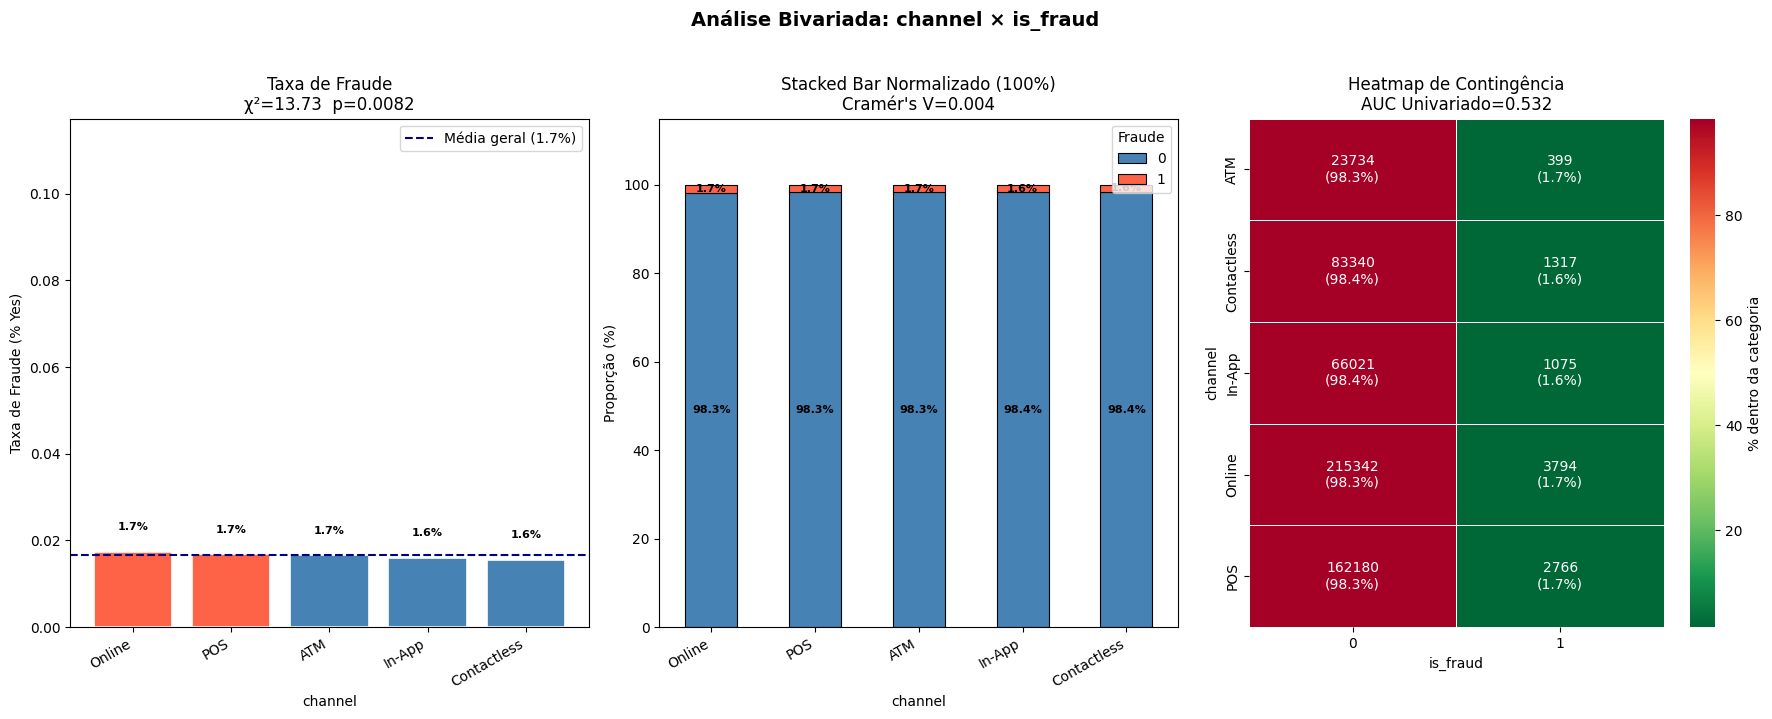

───────────────────────────────────────────────────────
  channel
  χ²=13.73  p=0.0082  |  Cramér's V=0.0042  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


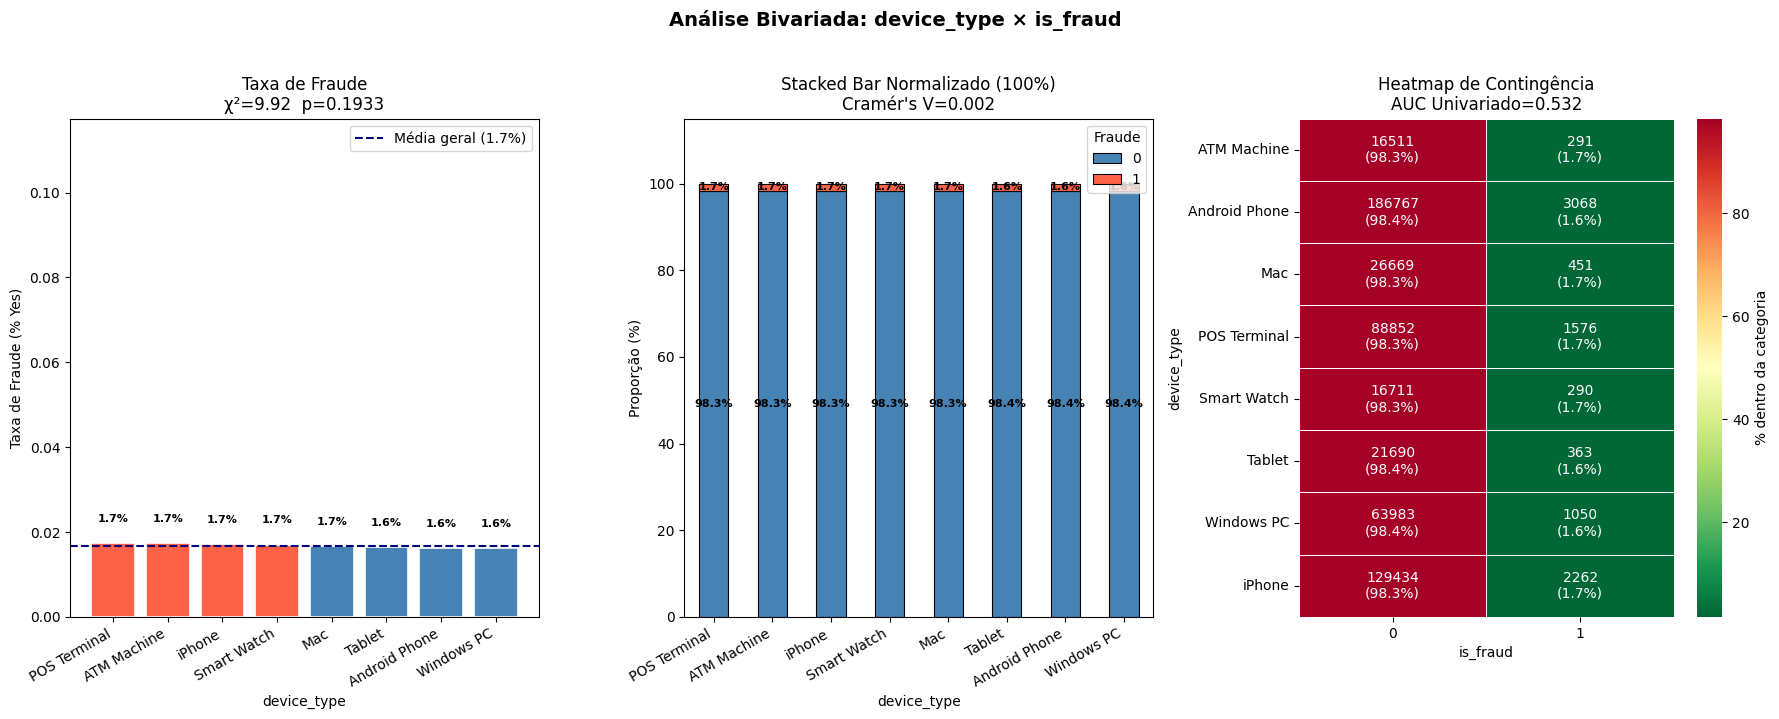

───────────────────────────────────────────────────────
  device_type
  χ²=9.92  p=0.1933  |  Cramér's V=0.0023  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


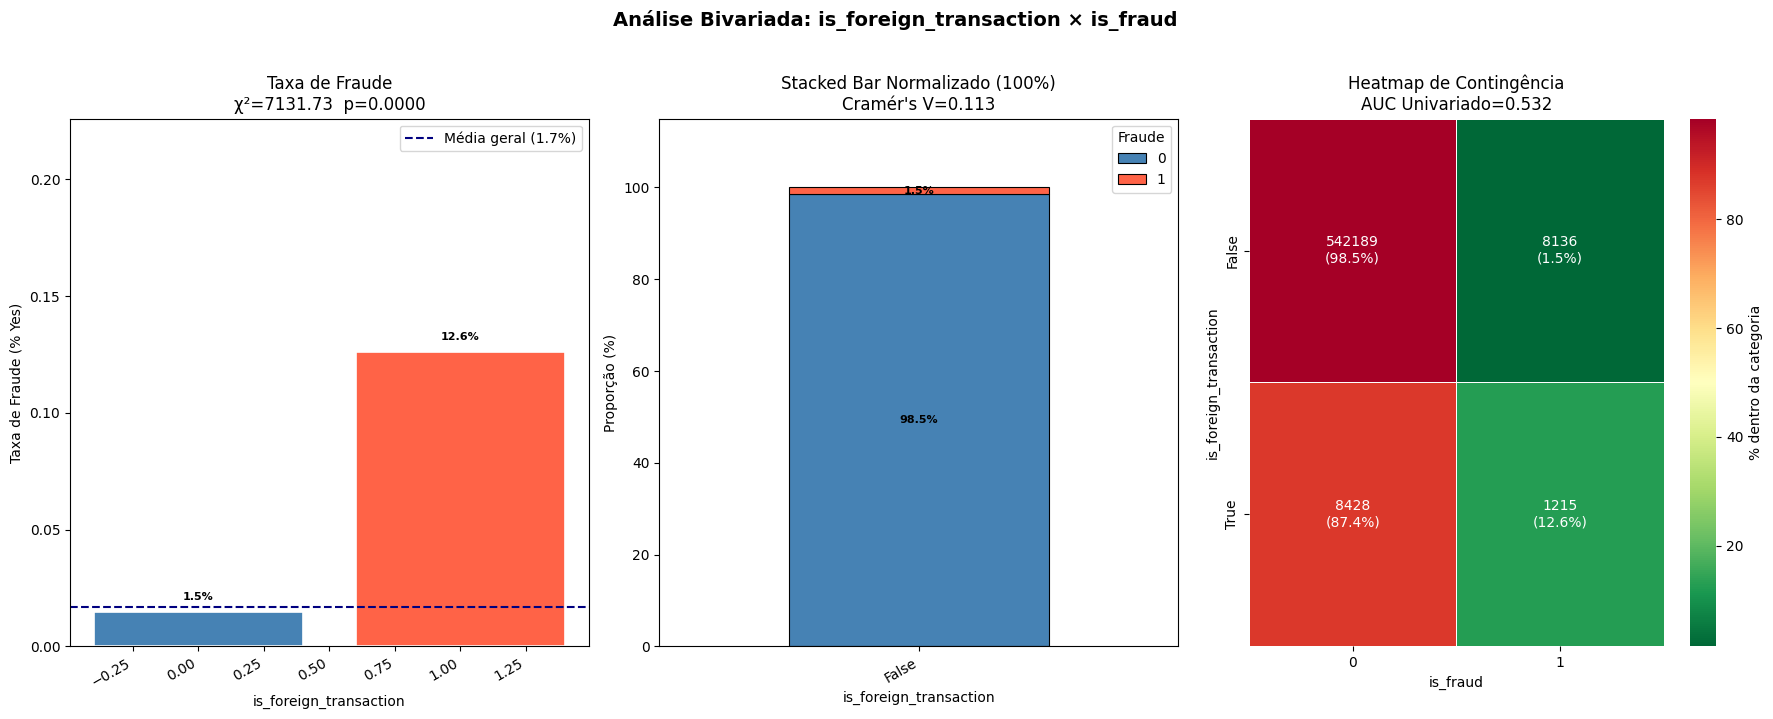

───────────────────────────────────────────────────────
  is_foreign_transaction
  χ²=7131.73  p=0.0000  |  Cramér's V=0.1128  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


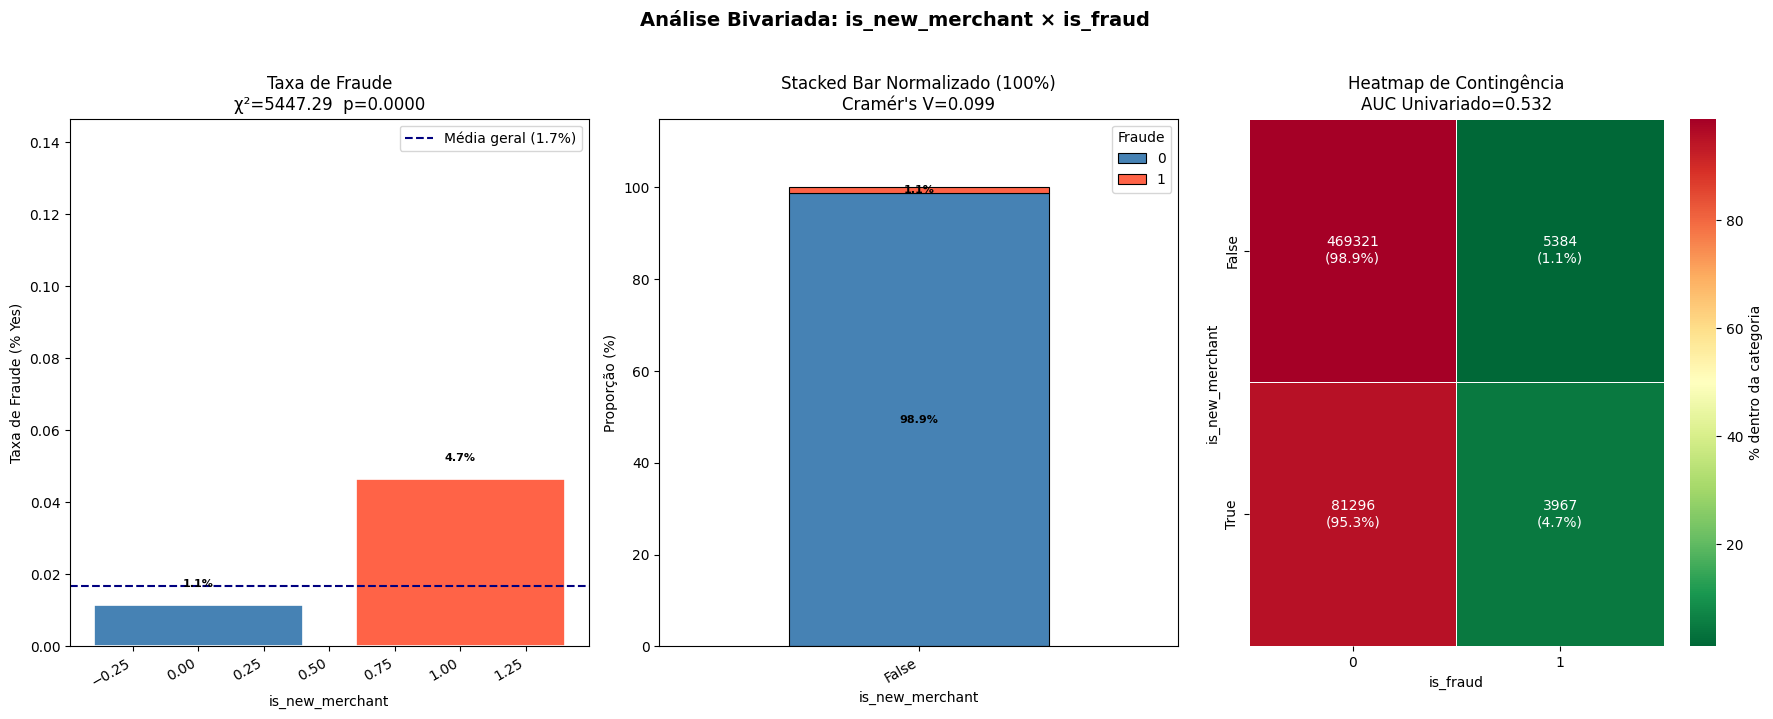

───────────────────────────────────────────────────────
  is_new_merchant
  χ²=5447.29  p=0.0000  |  Cramér's V=0.0986  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


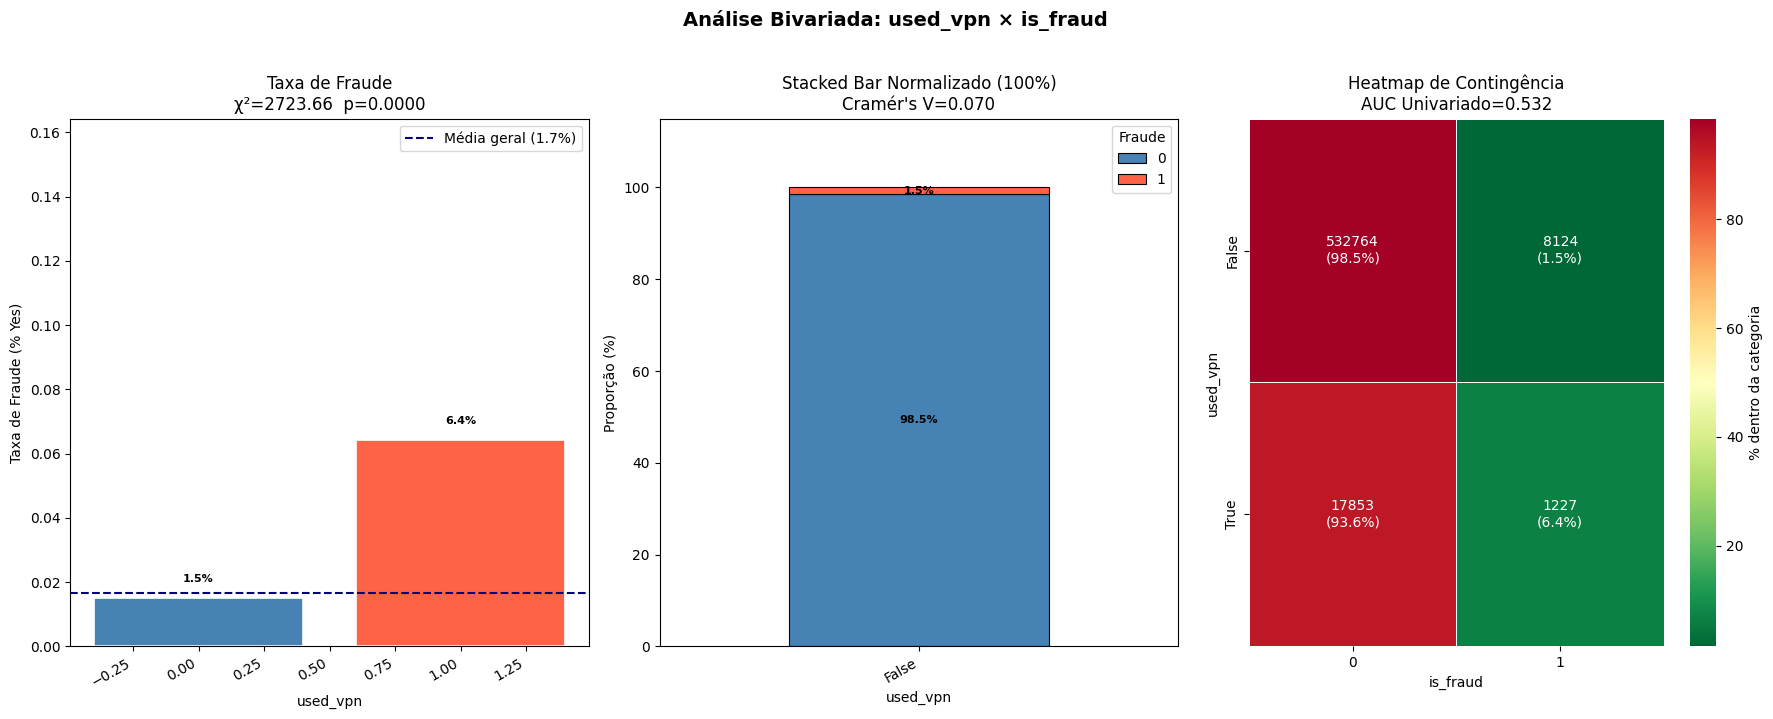

───────────────────────────────────────────────────────
  used_vpn
  χ²=2723.66  p=0.0000  |  Cramér's V=0.0697  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


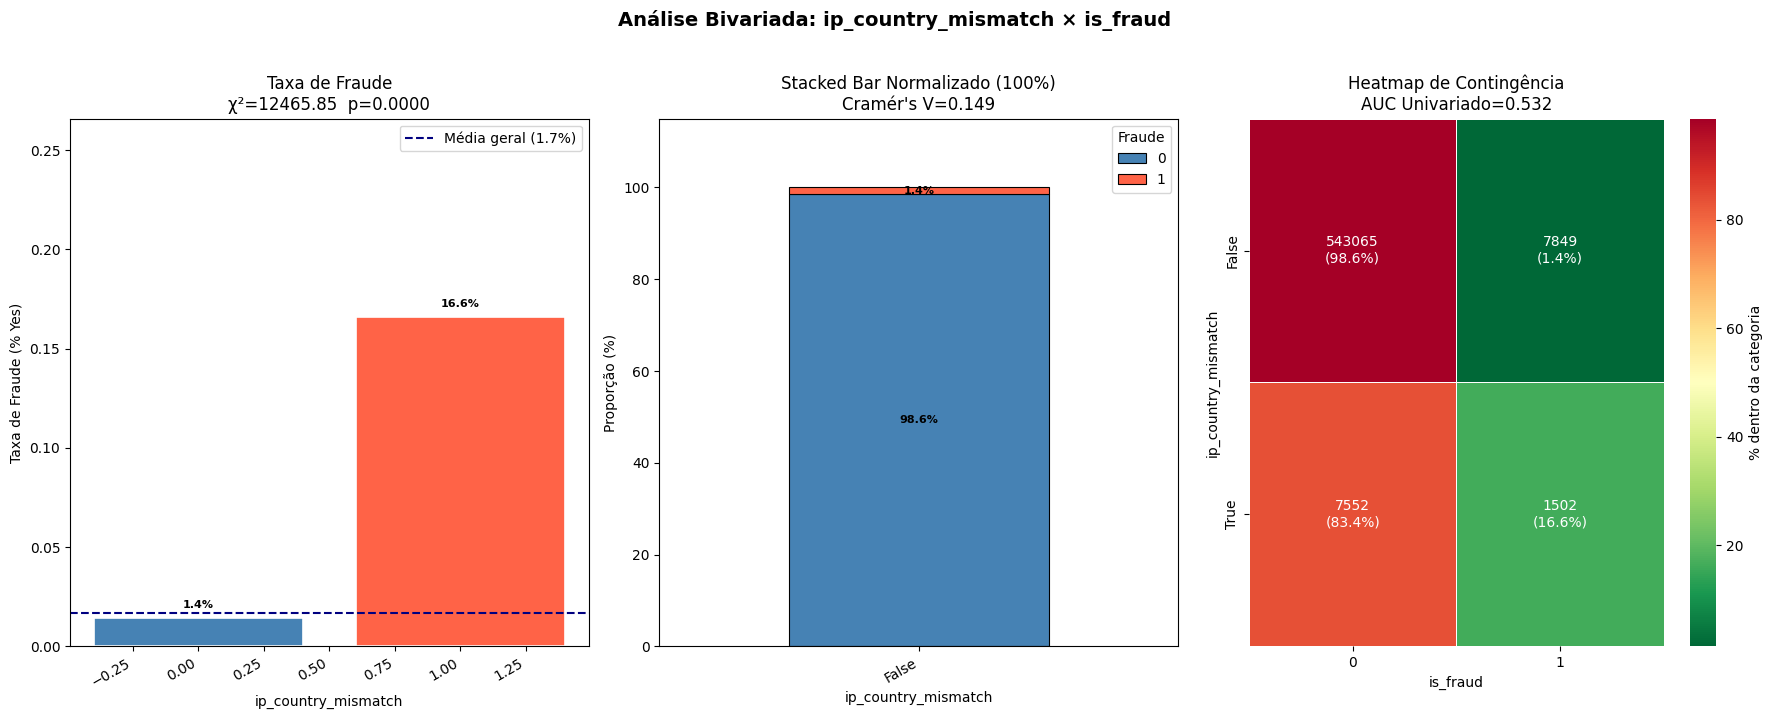

───────────────────────────────────────────────────────
  ip_country_mismatch
  χ²=12465.85  p=0.0000  |  Cramér's V=0.1492  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


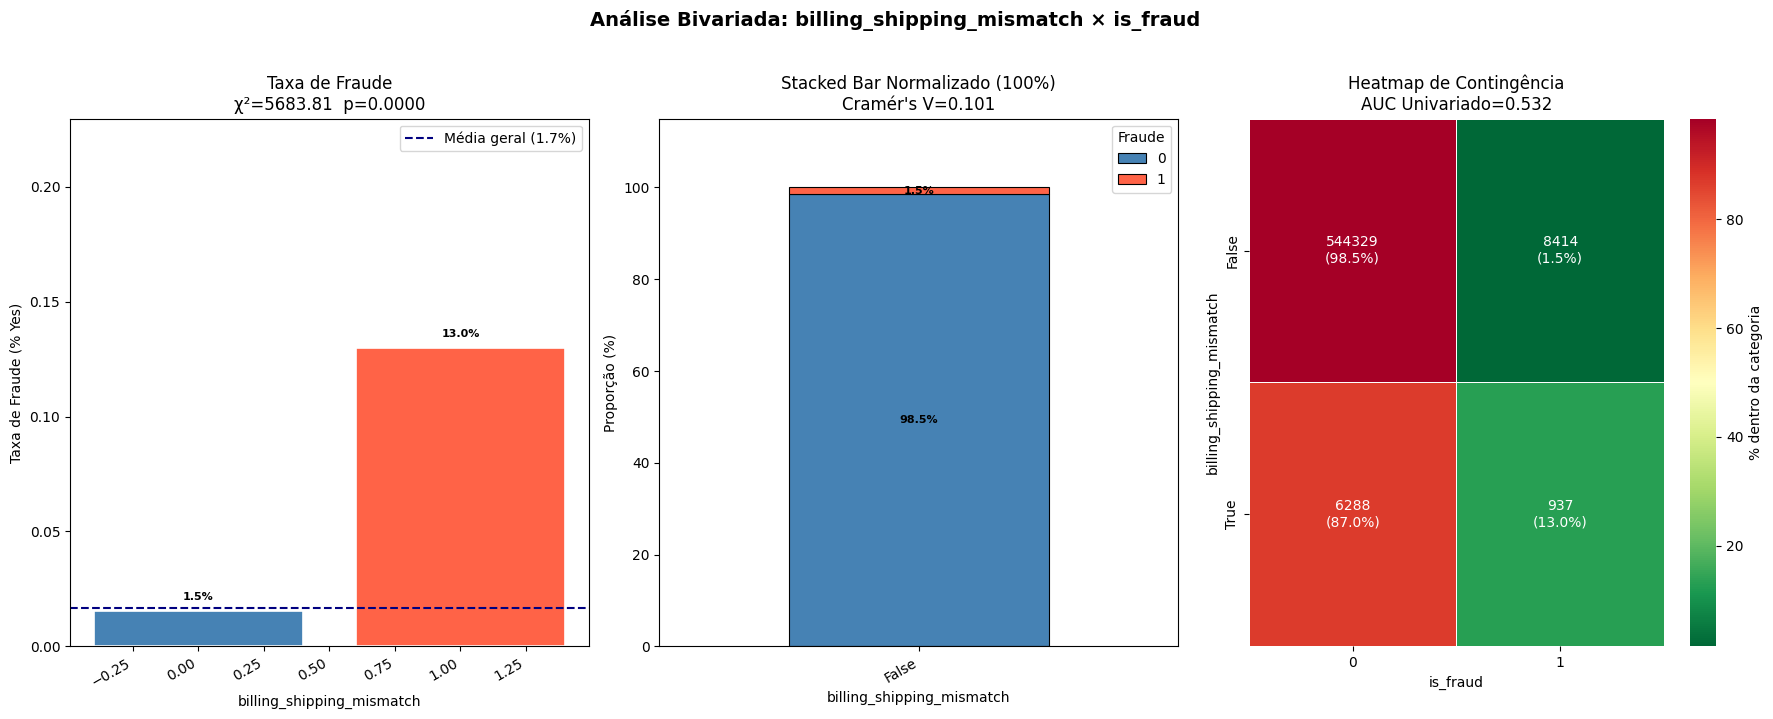

───────────────────────────────────────────────────────
  billing_shipping_mismatch
  χ²=5683.81  p=0.0000  |  Cramér's V=0.1007  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



C:\Users\marin\AppData\Local\Temp\ipykernel_95016\3421280415.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')


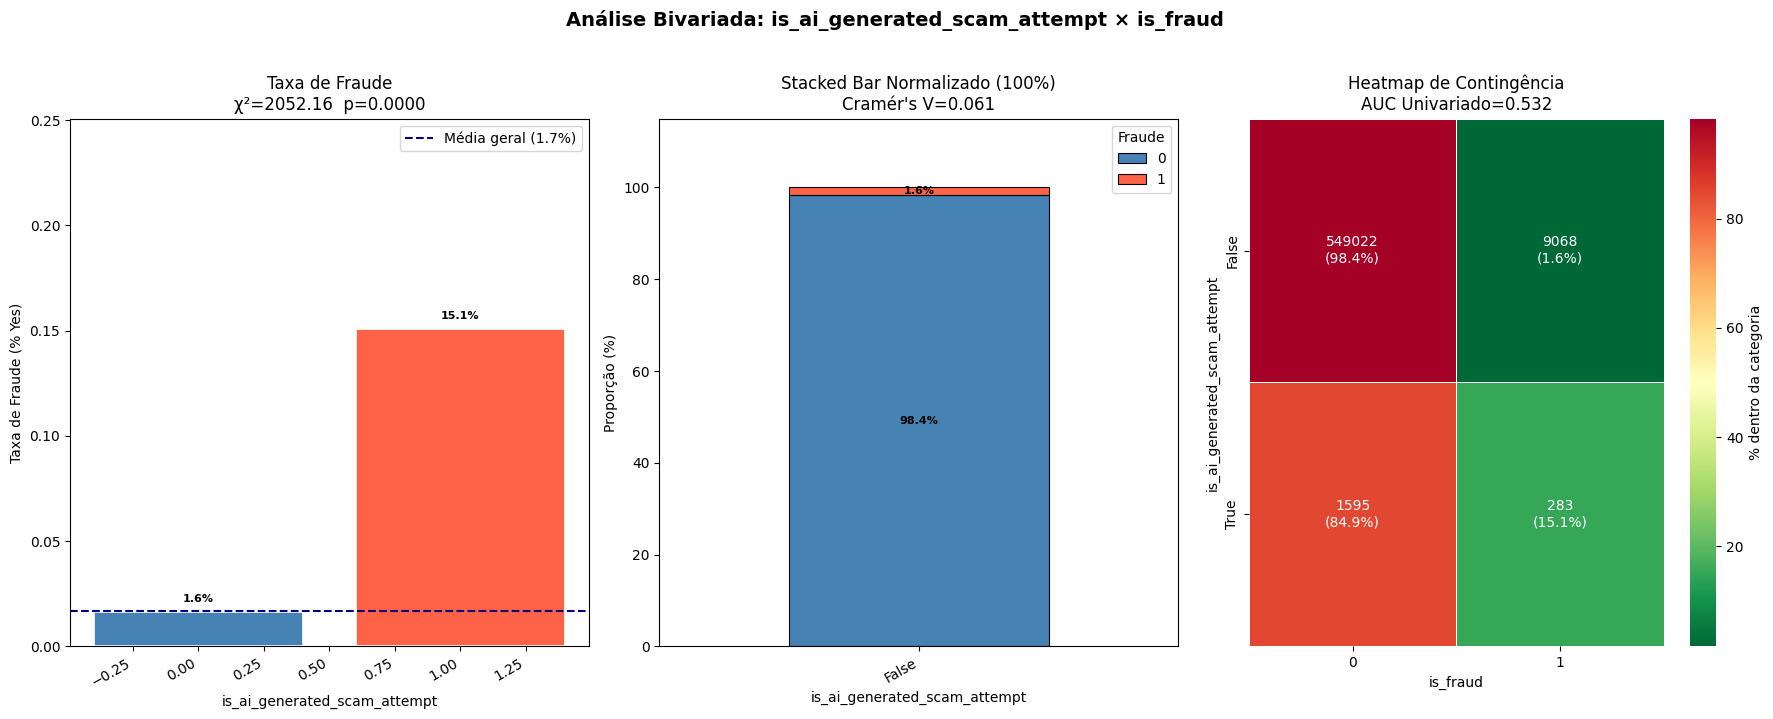

───────────────────────────────────────────────────────
  is_ai_generated_scam_attempt
  χ²=2052.16  p=0.0000  |  Cramér's V=0.0605  |  AUC=0.5325  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



In [84]:
col_target = 'is_fraud'
y_binary   = (df3[col_target] == 1).astype(int)
cat_cols   = categorical_att.columns
cat_cols   = [c for c in cat_cols if c != col_target]
 
for col in cat_cols:
    #============================================================
    # --- Métricas ---
    #============================================================
 
    contingency = pd.crosstab(df3[col], df3[col_target])
    chi2, p_value, _, _ = chi2_contingency(contingency)
    cv = cramers_v(df3[col], df3[col_target])
 
    model = LogisticRegression(max_iter=300).fit(x_enc, y_binary)
    auc   = roc_auc_score(y_binary, model.predict_proba(x_enc)[:, 1])
    auc   = max(auc, 1 - auc)
 
    fraud_rate = (
        df3.groupby(col)[col_target]
        .apply(lambda x: (x == 1).mean())
        .sort_values(ascending=False)
        .reset_index()
    )
    fraud_rate.columns = [col, 'Taxa Fraude']
    taxa_geral = y_binary.mean()
 
    #============================================================
    # --- Plots ---
    #============================================================
 
    fig, axes = plt.subplots(1, 3, figsize=(18, 7))
    fig.suptitle(f'Análise Bivariada: {col} × {col_target}',
                 fontsize=14, fontweight='bold', y=1.02)
   
    #============================================================
    # ── Plot 1: Taxa de Fraude por categoria ─────
    #============================================================
 
    bars = axes[0].bar(
        fraud_rate[col], fraud_rate['Taxa Fraude'],
        color=['tomato' if v > taxa_geral else 'steelblue'
               for v in fraud_rate['Taxa Fraude']],
        edgecolor='white', linewidth=1.2
    )
    axes[0].axhline(taxa_geral, color='navy', linestyle='--',
                    linewidth=1.5, label=f'Média geral ({taxa_geral:.1%})')
 
    for bar, val in zip(bars, fraud_rate['Taxa Fraude']):
        axes[0].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.005,
                     f'{val:.1%}', ha='center', fontsize=8, fontweight='bold')
 
    axes[0].set_title(f'Taxa de Fraude\nχ²={chi2:.2f}  p={p_value:.4f}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Taxa de Fraude (% Yes)')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
    axes[0].set_ylim(0, fraud_rate['Taxa Fraude'].max() + 0.1)
    axes[0].legend()
 
    #============================================================
    # ── Plot 2: Stacked Bar 100% normalizado ────────────
    #============================================================
 
    stacked = (
        pd.crosstab(df3[col], df3[col_target], normalize='index') * 100
    ).loc[fraud_rate[col]]   # mesma ordem do plot 1
 
    stacked[[0, 1]].plot(
        kind='bar', stacked=True, ax=axes[1],
        color=['steelblue', 'tomato'], edgecolor='black', linewidth=0.8
    )
 
    for idx, (_, row_data) in enumerate(stacked.iterrows()):
        axes[1].text(idx, row_data[0] / 2,
                     f"{row_data[0]:.1f}%", ha='center', va='center',
                     color='black', fontsize=8, fontweight='bold')
        axes[1].text(idx, row_data[0] + row_data[1] / 2,
                     f"{row_data[1]:.1f}%", ha='center', va='center',
                     color='black', fontsize=8, fontweight='bold')
 
    axes[1].set_title(f"Stacked Bar Normalizado (100%)\nCramér's V={cv:.3f}")
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Proporção (%)')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')
    axes[1].legend(title='Fraude', loc='upper right')
    axes[1].set_ylim(0, 115)
 
    #============================================================
    # ── Plot 3: Heatmap de contingência ───────────────
    #============================================================
 
    cont_abs = pd.crosstab(df3[col], df3[col_target])
    cont_pct = pd.crosstab(df3[col], df3[col_target], normalize='index') * 100
    annot    = cont_abs.astype(str) + '\n(' + cont_pct.round(1).astype(str) + '%)'
 
    sns.heatmap(cont_pct, annot=annot, fmt='', cmap='RdYlGn_r',
                ax=axes[2], linewidths=0.5,
                cbar_kws={'label': '% dentro da categoria'},
                annot_kws={'size': 10})
 
    axes[2].set_title(f'Heatmap de Contingência\nAUC Univariado={auc:.3f}')
    axes[2].set_xlabel(col_target)
    axes[2].set_ylabel(col)
 
    plt.tight_layout()
    plt.show()
 
    #============================================================
    # --- Resumo textual ---
    #============================================================
 
    discriminacao = '🟢 Alta' if auc >= 0.60 else '🟡 Média' if auc >= 0.55 else '🔴 Baixa'
    print(f"{'─'*55}")
    print(f"  {col}")
    print(f"  χ²={chi2:.2f}  p={p_value:.4f}  |  Cramér's V={cv:.4f}  |  AUC={auc:.4f}  |  Discriminação: {discriminacao}")
    print(f"{'─'*55}\n")

## 3.3 Análise Multivariada

### 3.3.1 Numerical and Categorical Attributes 

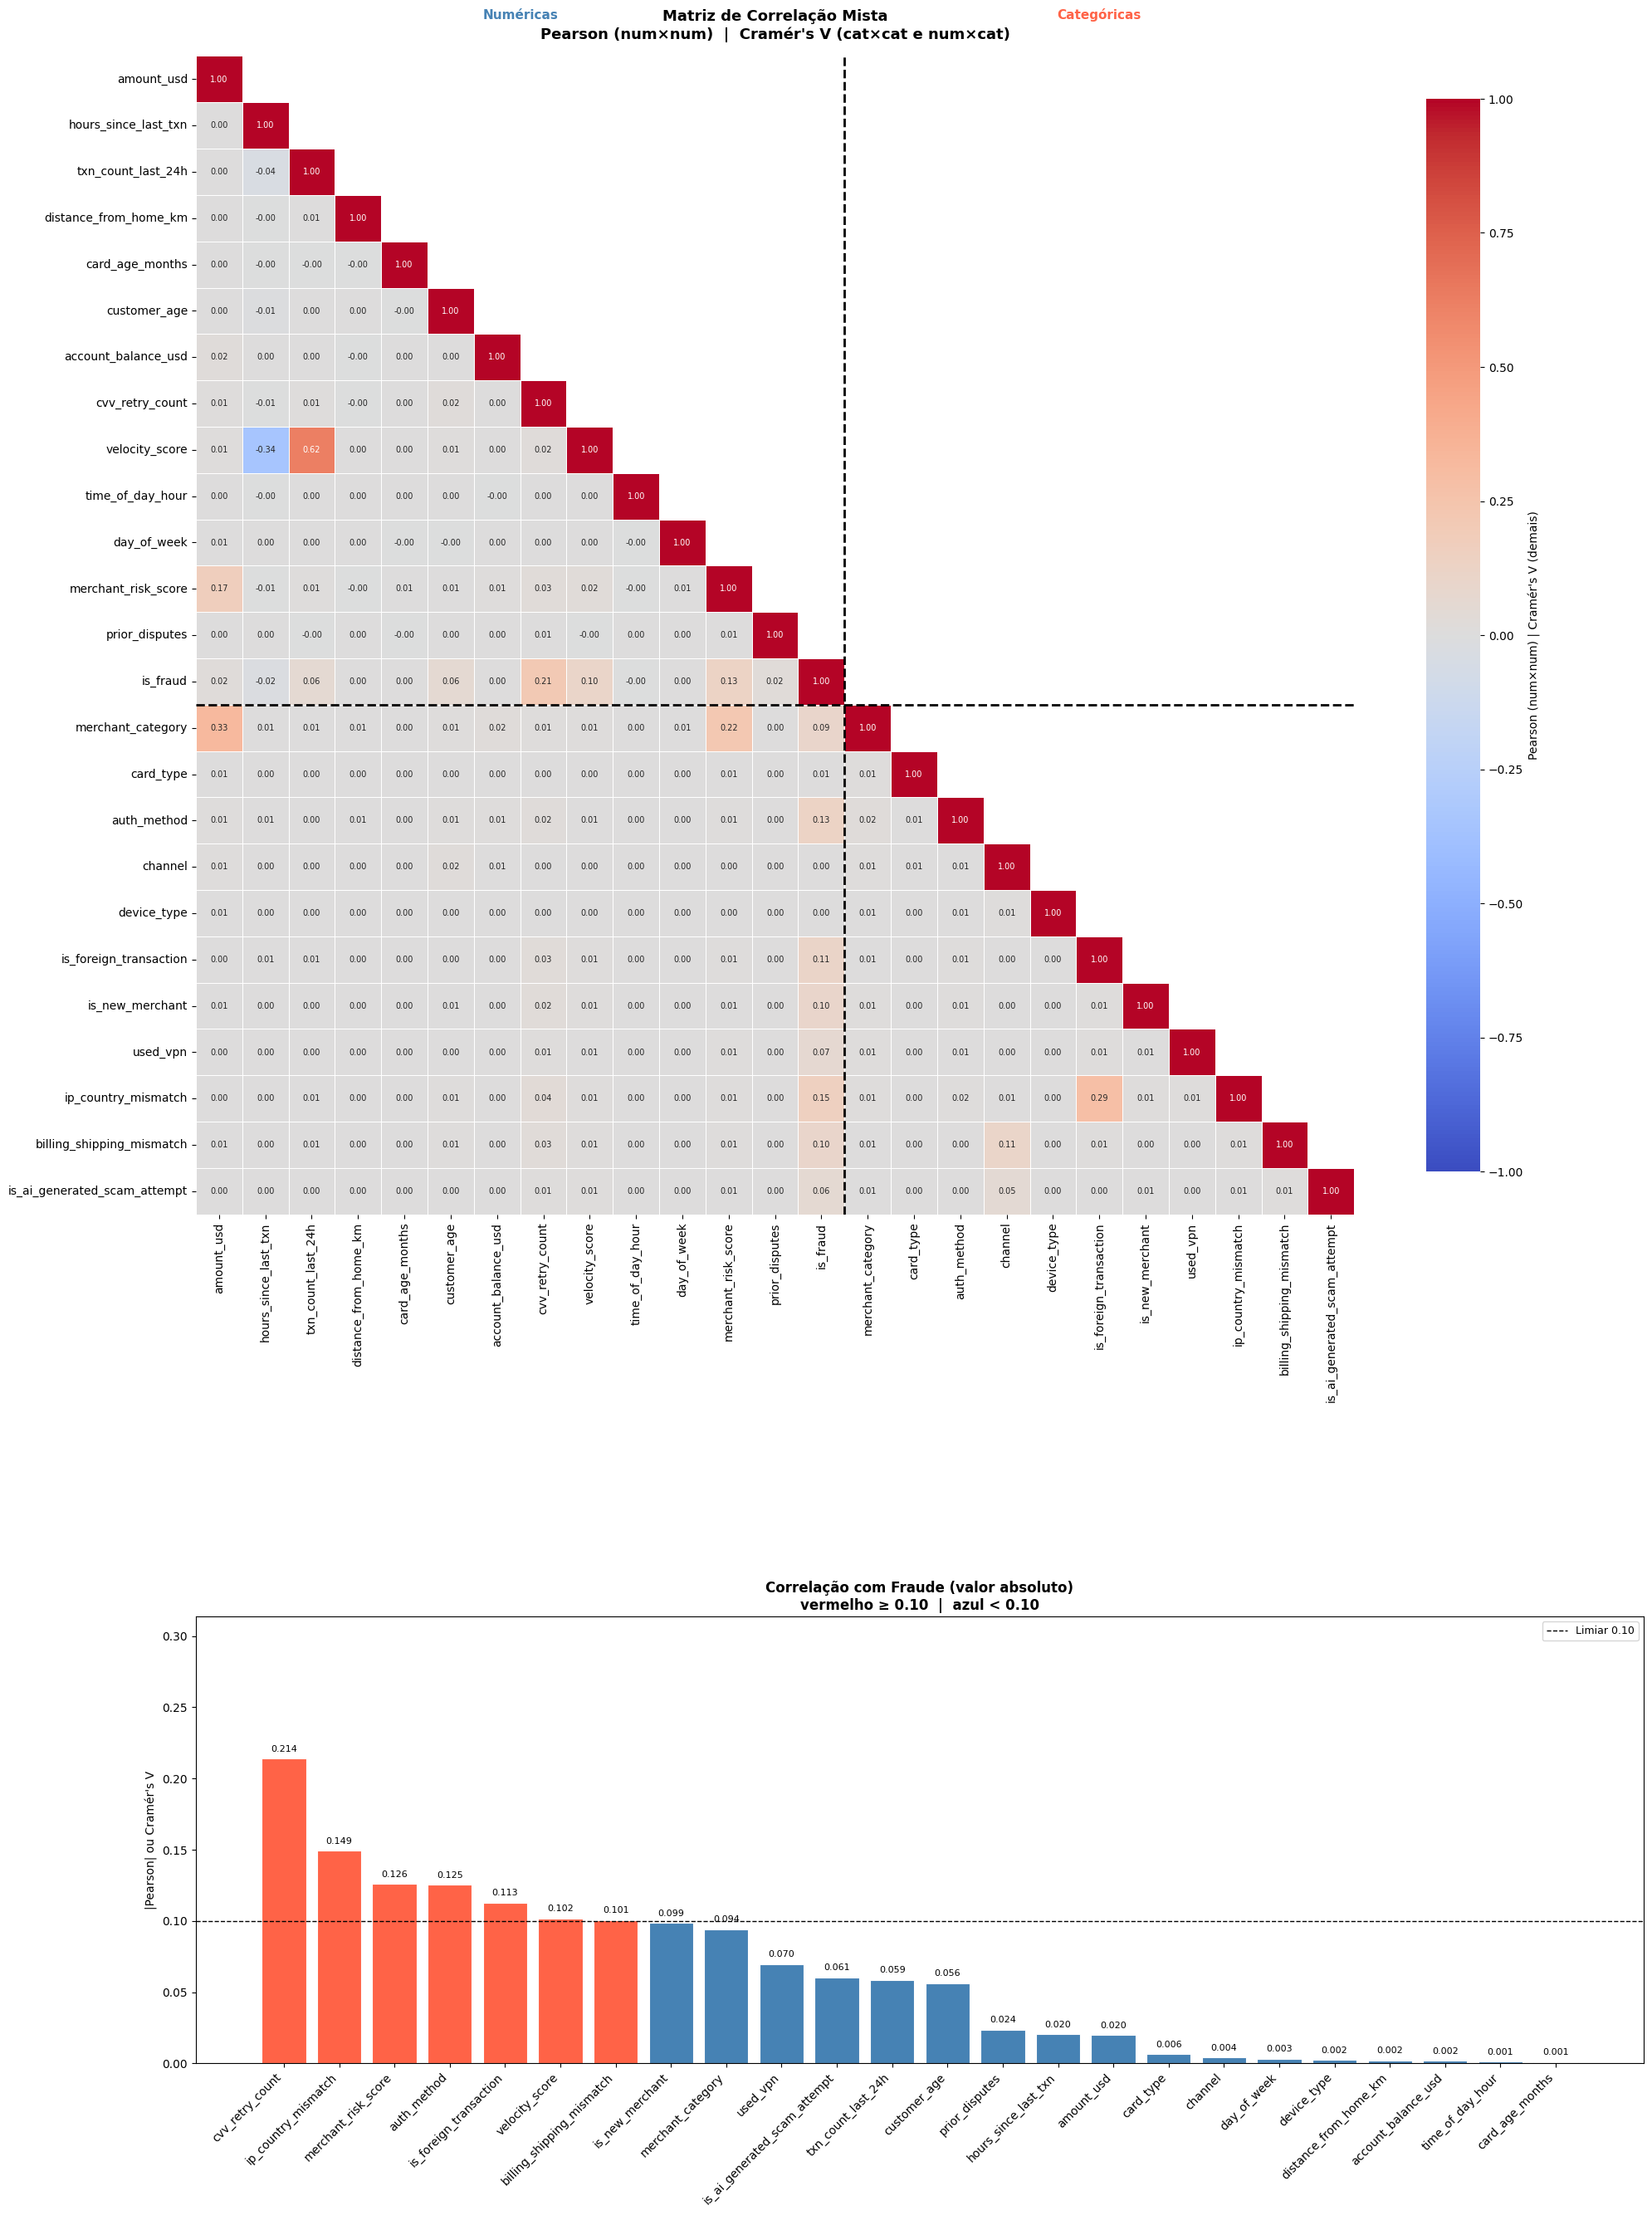


TOP CORRELAÇÕES COM FRAUDE
cvv_retry_count                 0.213884
ip_country_mismatch             0.149198
merchant_risk_score             0.126128
auth_method                     0.125265
is_foreign_transaction          0.112846
velocity_score                  0.101914
billing_shipping_mismatch       0.100740
is_new_merchant                 0.098621
merchant_category               0.094288
used_vpn                        0.069729
is_ai_generated_scam_attempt    0.060523
txn_count_last_24h              0.058667
customer_age                    0.056353
prior_disputes                  0.023757
hours_since_last_txn            0.020404
amount_usd                      0.019964
card_type                       0.006349
channel                         0.004168
day_of_week                     0.003388
device_type                     0.002283
distance_from_home_km           0.002117
account_balance_usd             0.001677
time_of_day_hour                0.001133
card_age_months              

In [78]:
# ================================================
# Matriz de Correlação Mista: Pearson + Cramér's V
# ================================================
 
TARGET = 'is_fraud'
LIMIAR = 0.10      # com 1,67% de fraude, correlações com o alvo são baixas por natureza
 
num_cols = [c for c in numerical_att.columns if c != 'id']
cat_cols = [c for c in categorical_att.columns if c != 'id']
 
all_cols = num_cols + cat_cols
 
# numérica com muitos valores -> 10 faixas, para o Cramér's V não tratar cada valor como categoria
def para_cramer(col):
    if col in num_cols and df3[col].nunique() > 10:
        return pd.qcut(df3[col], q=10, duplicates='drop').astype(str)
    return df3[col].astype(str)
 
n = len(all_cols)
corr_matrix = pd.DataFrame(np.zeros((n, n)), index=all_cols, columns=all_cols)
 
for i, col_a in enumerate(all_cols):
    for col_b in all_cols[:i + 1]:              # só metade da matriz: a outra é espelho
 
        a_is_num = col_a in num_cols
        b_is_num = col_b in num_cols
 
        if col_a == col_b:
            v = 1.0
        elif a_is_num and b_is_num:
            v = df3[col_a].corr(df3[col_b])
        else:
            v = cramers_v(para_cramer(col_a), para_cramer(col_b))
 
        corr_matrix.loc[col_a, col_b] = v
        corr_matrix.loc[col_b, col_a] = v
 
corr_matrix = corr_matrix.astype(float)
 
# ====================================================================
# ── Visualização: 2 linhas × 1 coluna ───────────
# ====================================================================
 
fig, axes = plt.subplots(2, 1, figsize=(20, 30),
                          gridspec_kw={'height_ratios': [4, 1]})
 
# ====================================================================
# ── Plot 1: Heatmap completo ────────────────────────────
# ====================================================================
 
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1) #faz o lado de cima da matriz do heatmapa ficar vazia
 
sns.heatmap(
    corr_matrix,
    mask=mask,
    ax=axes[0],
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    annot=True, fmt='.2f',
    annot_kws={'size': 7},
    linewidths=0.4,
    square=True,
    cbar_kws={'label': "Pearson (num×num) | Cramér's V (demais)", 'shrink': 0.6}
)
 
n_num = len(num_cols)
axes[0].axhline(n_num, color='black', linewidth=2, linestyle='--')
axes[0].axvline(n_num, color='black', linewidth=2, linestyle='--')
 
axes[0].text(n_num / 2, -0.8, 'Numéricas', ha='center',
             fontsize=11, fontweight='bold', color='steelblue')
axes[0].text(n_num + len(cat_cols) / 2, -0.8, 'Categóricas', ha='center',
             fontsize=11, fontweight='bold', color='tomato')
 
axes[0].set_title("Matriz de Correlação Mista\nPearson (num×num)  |  Cramér's V (cat×cat e num×cat)",
                   fontsize=13, fontweight='bold', pad=15)
axes[0].tick_params(axis='x', rotation=90)
axes[0].tick_params(axis='y', rotation=0)
 
# ====================================================================
# ── Plot 2: Ranking de correlação com Fraude ──────────────────
# ====================================================================
 
fraud_corr = (
    corr_matrix[TARGET]
    .drop(TARGET)
    .abs()
    .sort_values(ascending=False)
)
 
colors = ['tomato' if v >= LIMIAR else 'steelblue' for v in fraud_corr.values]
 
axes[1].bar(fraud_corr.index, fraud_corr.values,
            color=colors, edgecolor='white', linewidth=0.8)
axes[1].axhline(LIMIAR, color='black', linestyle='--',
                linewidth=1, label=f'Limiar {LIMIAR:.2f}')
 
for i, (feat, val) in enumerate(fraud_corr.items()):
    axes[1].text(i, val + 0.005, f'{val:.3f}',
                 ha='center', fontsize=8, color='black')
 
axes[1].set_title(f"Correlação com Fraude (valor absoluto)\nvermelho ≥ {LIMIAR:.2f}  |  azul < {LIMIAR:.2f}",
                   fontsize=12, fontweight='bold')
axes[1].set_ylabel("|Pearson| ou Cramér's V")
axes[1].set_xticks(range(len(fraud_corr)))
axes[1].set_xticklabels(fraud_corr.index, rotation=45, ha='right')
axes[1].set_ylim(0, fraud_corr.max() + 0.1)
axes[1].legend(fontsize=9)
 
plt.tight_layout(h_pad=4)
plt.show()
 
# ====================================================================
# --- Resumo textual ---
# ====================================================================
 
print(f"\n{'='*50}")
print("TOP CORRELAÇÕES COM FRAUDE")
print(f"{'='*50}")
print(fraud_corr.to_string())

# 4.0 DATA PREPARATION

## 4.1 Feature Selection

In [ ]:
df4 = df3.copy()

In [ ]:
del (df3)

In [ ]:
# --- Reverter dummies para nome original ---
def to_original(col):
    return col.split('__SEP__')[0] if '__SEP__' in col else col

In [ ]:
# =============================================================
# ---------------- Wrapper Methods (Boruta) -------------------
# =============================================================
 
"""No Boruta, cada feature ganha uma cópia "sombra" com os valores embaralhados
(mesma distribuição, nenhuma relação com o alvo). A cada rodada, um Random Forest
é treinado com as originais + as sombras, e cada original é comparada com a MELHOR
sombra. Ao fim de várias rodadas, um teste estatístico sobre quantas vezes cada
original venceu decide: confirmada, tentativa ou rejeitada."""
 
# =============================================================
# --- Preparação dos dados ---
# =============================================================
 
x = df4.drop(columns=['is_fraud', 'id'])
y = df4['is_fraud']
 
x_boruta = pd.get_dummies(x, prefix_sep='__SEP__', dtype=int)
 
def to_original(col):
    return col.split('__SEP__')[0]
 
# =============================================================
# --- Modelo e Boruta ---
# =============================================================
 
rf = RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=42)
 
boruta = BorutaPy(
    rf,
    n_estimators='auto',
    verbose=0,
    random_state=42
).fit(x_boruta.values, y.values)
 
# =============================================================
# --- Resultados por dummy ---
# =============================================================
 
confirmed_boruta = x_boruta.columns[boruta.support_].tolist()
tentative_boruta = x_boruta.columns[boruta.support_weak_].tolist()
rejected_boruta  = x_boruta.columns[~boruta.support_ & ~boruta.support_weak_].tolist()
 
# =============================================================
# --- Volta para o nome original (junta as dummies) ---
# =============================================================
 
confirmed_boruta = sorted(set(to_original(c) for c in confirmed_boruta))
tentative_boruta = sorted(set(to_original(c) for c in tentative_boruta))
rejected_boruta  = sorted(set(to_original(c) for c in rejected_boruta))
 
tentative_boruta = [c for c in tentative_boruta if c not in confirmed_boruta]
rejected_boruta  = [c for c in rejected_boruta
                    if c not in confirmed_boruta and c not in tentative_boruta]
 
# =============================================================
# --- Resumo ---
# =============================================================
 
ranking = pd.Series(boruta.ranking_, index=x_boruta.columns).sort_values()
 
print(f'Confirmadas ({len(confirmed_boruta)}): {confirmed_boruta}')
print(f'Tentativas  ({len(tentative_boruta)}): {tentative_boruta}')
print(f'Rejeitadas  ({len(rejected_boruta)}): {rejected_boruta}')
display(ranking.to_frame('Ranking Boruta'))
 

Confirmadas (16): ['amount_usd', 'auth_method', 'billing_shipping_mismatch', 'customer_age', 'cvv_retry_count', 'hours_since_last_txn', 'ip_country_mismatch', 'is_ai_generated_scam_attempt', 'is_foreign_transaction', 'is_new_merchant', 'merchant_category', 'merchant_risk_score', 'prior_disputes', 'txn_count_last_24h', 'used_vpn', 'velocity_score']
Tentativas  (0): []
Rejeitadas  (8): ['account_balance_usd', 'card_age_months', 'card_type', 'channel', 'day_of_week', 'device_type', 'distance_from_home_km', 'time_of_day_hour']


,Ranking Boruta
amount_usd,1
hours_since_last_txn,1
txn_count_last_24h,1
customer_age,1
cvv_retry_count,1
is_foreign_transaction,1
merchant_risk_score,1
velocity_score,1
is_new_merchant,1
used_vpn,1


## 4.2 Preparação de Variáveis

In [ ]:
# Transformação, Escalonamento e Encoding (Transformação Assimetria (Skewness - log/YJ), Rescaling (Normalização/Padronização) e Encorders)
[
'amount_usd',
'hours_since_last_txn',
'txn_count_last_24h',
'customer_age',
'cvv_retry_count',
'is_foreign_transaction',
'merchant_risk_score',
'velocity_score',
'is_new_merchant',
'used_vpn',
'prior_disputes',
'merchant_category__SEP__Electronics',
'merchant_category__SEP__Crypto Exchange',
'is_ai_generated_scam_attempt',
'billing_shipping_mismatch',
'ip_country_mismatch',
'merchant_category__SEP__Gift Cards',
'merchant_category__SEP__Gaming',
'merchant_category__SEP__Online Retail',
'auth_method__SEP__No Authentication',
'auth_method__SEP__Biometric',
'auth_method__SEP__PIN',
'distance_from_home_km',
'merchant_category__SEP__Groceries',
'account_balance_usd',
'card_age_months',
'merchant_category__SEP__Streaming',
'time_of_day_hour',
'merchant_category__SEP__Restaurants',
'auth_method__SEP__3D Secure',
'auth_method__SEP__OTP',
'day_of_week',
'merchant_category__SEP__Travel',
'merchant_category__SEP__Healthcare',
'channel__SEP__Online',
'merchant_category__SEP__Fuel',
'card_type__SEP__Amex',
'device_type__SEP__Windows PC',
'channel__SEP__POS',
'card_type__SEP__Mastercard',
'device_type__SEP__iPhone',
'card_type__SEP__Visa',
'merchant_category__SEP__Utilities',
'channel__SEP__Contactless',
'channel__SEP__In-App',
'device_type__SEP__ATM Machine',
'device_type__SEP__POS Terminal',
'device_type__SEP__Android Phone',
'device_type__SEP__Mac',
'device_type__SEP__Tablet',
'card_type__SEP__RuPay',
'channel__SEP__ATM',
'device_type__SEP__Smart Watch',
'card_type__SEP__Discover',
]